# Extreme Events and Stock Market Behavior
### Why markets fall the way they do, how they recover, and how to stress-test a portfolio against each type of shock
**DATA 400 project**

**Research question.** How do different types of extreme events move the U.S. stock market, why do some crashes heal in months while others take years, and how should a portfolio be stress-tested against each type of shock?

This notebook is the analytical backbone of the written report. Every section starts with the **market question and the economic intuition**; the data is used to test that intuition, not to replace it.

| Part | Sections | What it does |
|---|---|---|
| **0** | 0 | Framework: why stock prices fall and recover |
| **Setup** | 1–2 | Configuration, data download and freeze |
| **Part 1: Finding the events** | 3–10b | Rule-based detection of extreme episodes, labelling, 17 study units, depth and recovery |
| **Part 2: Understanding the behavior** | 11–15 | Shock families, what moves with stocks, hedges, sector rotation, macro backdrop and policy response |
| **Part 2: Stress testing** | 16–20c | Portfolios, historical replay, family scenarios with walk-forward and leave-one-out validation, calm-vs-stress risk, reverse stress test, **why portfolios won or lost (20b)**, **forward-looking what-if scenarios (20c)** |
| **Robustness** | 21 | Reclassification, consolidation and leave-one-out sensitivity of every headline conclusion |
| **Conclusions** | 22–23 | Findings generated from the data, limitations, outputs, references |

**What kind of study this is.** Part 1 and Sections 11–15 are a **historical (retrospective) analysis**: crisis windows, troughs and recoveries are identified with hindsight, which is appropriate for describing what happened. Only the walk-forward test in Section 18b mimics what an analyst could have known at the time. Claims are worded accordingly: *associated with*, not *predicts*.

**Reproducibility.** All parameters are in one configuration cell and saved to `outputs/config.json`. Market data is downloaded once and frozen in `data/raw/`; later runs read the frozen files. Run top to bottom (*Runtime → Run all*).

## 0. Framework: why stock prices fall, and why some falls heal faster

A stock index is worth the present value of future corporate profits:

$$P \;=\; \frac{\text{expected cash flows}}{\text{discount rate} - \text{growth}}, \qquad \text{discount rate} = \text{risk-free rate} + \text{risk premium}$$

A crash must come through one (or more) of three doors:

| Door | What changes | Typical trigger | What else moves | Recovery |
|---|---|---|---|---|
| **1. Cash flows** | Profits are permanently lower | Recession, credit crisis, pandemic | Treasury yields **fall** (flight to safety, rate cuts), credit spreads widen, cyclical sectors lead the fall | Slow if the damage is real (banks, balance sheets); fast if policy replaces lost income |
| **2. Risk-free rate** | Rates rise | Inflation, central-bank tightening | Stocks **and** bonds fall together; long-duration (tech, growth) stocks hurt most | Slow: the Fed cannot rescue a market it is deliberately cooling |
| **3. Risk premium** | Investors demand more return for the same risk | Fear, uncertainty, war, forced selling | Volatility spikes, safe havens (Treasuries, gold, dollar or yen) rally | Fast once the uncertainty resolves; profits were never really hit |

This split follows Campbell & Vuolteenaho (2004), who show that cash-flow ("bad beta") news is permanent while discount-rate ("good beta") news tends to reverse. Two more forces decide the *speed* of recovery:

- **Policy response.** If the central bank can cut rates and the government can spend, the risk premium collapses quickly (COVID 2020). If inflation ties the Fed's hands, there is no rescue (2022).
- **Starting conditions.** A shock hitting an expensive, leveraged market falls further than the same shock hitting a cheap, unleveraged one.

**Hypotheses tested in this notebook**

| | Hypothesis | Where it is tested |
|---|---|---|
| H1 | Shocks that hit **cash flows or the financial system** fall deeper and recover more slowly than **risk-premium** (sudden event) shocks | Sections 10, 15 |
| H2 | **Bonds hedge stocks** in growth/credit shocks but **fail** in rate/inflation shocks | Section 13 |
| H3 | **Defensive sectors** outperform in the fall; **cyclicals** lead the rebound; which cyclicals lead depends on the shock | Section 14 |
| H4 | Recovery is faster when **policy can ease** | Section 15 |
| H5 | Stress tests built **by shock type** predict losses better than one generic crash scenario, and risk models calibrated in calm markets understate crisis losses | Sections 18, 18b, 19 |

## 1. Setup and configuration
The first cell installs `yfinance` (the only package Colab lacks). The second cell imports everything and holds **all** settings; it must run before any later cell. If you ever see `name ... is not defined`, run it again.

In [1022]:
# Installs yfinance if missing (Google Colab or Jupyter). If Colab asks to restart, restart, then run the NEXT cell onwards.
!pip install -q yfinance

In [1023]:
import json, platform, io, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 150)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("Python", platform.python_version(), "| pandas", pd.__version__,
      "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)

# ---------------------------------------------------------------- CONFIGURATION
CONFIG = {
    # ---- data
    "download_start": "1999-01-01",     # one extra year for volatility warm-up and 1-year lookbacks
    "download_end": "2026-10-16",       # exclusive end date: fixes the sample (last trading day 2026-10-15) so a fresh download matches the report
    "analysis_start": "2000-01-01",
    "refresh_data": False,              # True = download again and overwrite the frozen files
    "assets": {                         # name -> Yahoo Finance ticker (prices adjusted for dividends)
        "sp500": "^GSPC",               # S&P 500 price index (event detection)
        "sp500_tr": "VFINX",            # S&P 500 index fund, total return (portfolios)
        "long_tsy": "VUSTX",            # long-term Treasury fund
        "int_tsy": "VFITX",             # intermediate Treasury fund
        "gold": "GC=F", "oil": "CL=F", "dollar": "DX-Y.NYB",
        "vix": "^VIX", "ust10y": "^TNX", "ust3m": "^IRX",
        "tech": "XLK", "financials": "XLF", "energy": "XLE", "health": "XLV",
        "cons_disc": "XLY", "staples": "XLP", "industrials": "XLI",
        "materials": "XLB", "utilities": "XLU",
    },
    "fred_series": {"credit_spread": "BAA10Y", "cpi": "CPIAUCSL",     # optional macro data
                    "dgs10": "DGS10", "dtb3": "DTB3"},                 # official yields, used to verify units
    # ---- Part 1: detection
    "ewma_lambda": 0.94, "ewma_seed_days": 60, "z_cut": 3.0,
    "fixed_cut": 0.025, "pct_cut": 0.99,
    "merge_gap_days": 20, "pre_peak_window": 60,
    "hp_lambda_monthly": 129600, "bloom_sd": 1.65,
    "min_drawdown_pct": -10.0,
    "event_trough_after_days": 20, "cycle_peak_window": 250, "bigger_bear_gap": 10.0,
    # ---- Part 2: behavior
    "rebound_days": 60,                 # rebound phase: 60 trading days after the trough
    "policy_window_days": 126,          # policy response: change in 3-month yield over 6 months
    "rolling_corr_days": 252,
    # ---- Part 2: stress test
    "portfolios": {
        "S&P 500":     {"sp500_tr": 1.0},
        "60/40":       {"sp500_tr": 0.6, "int_tsy": 0.4},
        "Tech tilt":   {"sp500_tr": 0.5, "tech": 0.5},
        "Defensive":   {"staples": 1/3, "health": 1/3, "utilities": 1/3},
        "Diversified": {"sp500_tr": 0.4, "long_tsy": 0.3, "int_tsy": 0.15, "gold": 0.15},
    },
    "oos_split_date": "2020-01-01",     # scenarios built from units before this date, tested on units after
    "var_lookback_days": 250, "var_z": 2.326,   # parametric 99% VaR
    "vix_regime_threshold": 25.0,       # ex-ante high-fear regime: previous VIX close above this
    # ---- Section 20c: forward-looking what-if scenarios (moderate level; drivers in %, yield change in bp)
    "what_if_scenarios": {
        "Deflationary bust":  {"sp": -35, "dy_bp": -150, "oil": -40, "gold": 15,  "anchor": "2008 crisis, COVID"},
        "Stagflation":        {"sp": -25, "dy_bp": 150,  "oil": 40,  "gold": 0,   "anchor": "2022, but with oil"},
        "Oil supply shock":   {"sp": -12, "dy_bp": 50,   "oil": 80,  "gold": -10, "anchor": "Iran war 2026, larger"},
        "Sell America":       {"sp": -20, "dy_bp": 75,   "oil": -10, "gold": 15,  "anchor": "April 2025 tariffs, larger"},
        "Dash for cash":      {"sp": -30, "dy_bp": 25,   "oil": -40, "gold": -10, "anchor": "March 2020 liquidity squeeze"},
    },
    "what_if_severity": {"Mild": 0.5, "Moderate": 1.0, "Severe": 1.5},
    "reverse_target_loss_pct": -20.0,
    "replay_horizon_days": 1260,        # follow each portfolio up to 5 years for recovery
}

SECTORS = ["tech", "financials", "energy", "health", "cons_disc", "staples",
           "industrials", "materials", "utilities"]
DEFENSIVE = ["staples", "health", "utilities"]
CYCLICAL = ["tech", "financials", "energy", "cons_disc", "industrials", "materials"]
CROSS_ASSETS = ["sp500_tr", "int_tsy", "long_tsy", "gold", "oil", "dollar"]

DATA_RAW, OUT, FIG = Path("data/raw"), Path("outputs"), Path("figures")
for p in (DATA_RAW, OUT, FIG):
    p.mkdir(parents=True, exist_ok=True)
(OUT / "config.json").write_text(json.dumps(CONFIG, indent=2))

# ---- chart style: muted ink for data, a validated 4-colour set for shock families
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
FAMILY_STYLE = {   # colour + marker, so identity never relies on colour alone
    "Growth & credit":   (BLUE, "o"),
    "Rates & inflation": (ORANGE, "s"),
    "Valuation unwind":  (AQUA, "^"),
    "Sudden event":      (YELLOW, "D"),
}
DIVERGING = LinearSegmentedColormap.from_list("div", [ORANGE, "#f2f1ed", BLUE])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
})
print("Config saved to", OUT / "config.json")

Python 3.12.4 | pandas 2.2.2 | numpy 1.26.4 | matplotlib 3.8.4
Config saved to outputs/config.json


## 2. Data
| Data | Source | Used for |
|---|---|---|
| S&P 500 index, VIX, 10-year and 3-month Treasury yields | Yahoo Finance | Event detection, fear gauge, rates |
| S&P 500 fund (VFINX), Treasury funds (VUSTX long, VFITX intermediate) | Yahoo Finance, dividend-adjusted | Total returns for portfolios; these funds go back before 2000 |
| Gold and oil futures, U.S. dollar index | Yahoo Finance | Safe havens and commodity shocks (gold and oil start Aug 2000) |
| 9 Select Sector SPDR ETFs | Yahoo Finance | Sector rotation (start Dec 1998) |
| Baa corporate spread, CPI | FRED (optional) | Credit stress, inflation backdrop |

All series are aligned to S&P 500 trading days (other markets' holidays are forward-filled for at most 5 days). The first run downloads and freezes everything; later runs read the frozen files.

In [1025]:
PRICES_FILE, FRED_FILE, META_FILE = DATA_RAW / "market_prices.csv", DATA_RAW / "macro_fred.csv", DATA_RAW / "data_metadata.json"
ASSETS = CONFIG["assets"]

def download_market():
    import yfinance as yf
    raw = yf.download(list(ASSETS.values()), start=CONFIG["download_start"], end=CONFIG["download_end"],
                      auto_adjust=True, progress=False)
    close = raw["Close"] if isinstance(raw.columns, pd.MultiIndex) else raw
    close = close.rename(columns={v: k for k, v in ASSETS.items()})
    close = close[[c for c in ASSETS if c in close.columns]]
    close.index.name = "Date"
    close.to_csv(PRICES_FILE)
    return yf.__version__

def download_fred(only=None):
    frames = []
    for name, sid in CONFIG["fred_series"].items():
        if only is not None and name not in only:
            continue
        try:
            s = pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}")
            s.columns = ["Date", name]
            s["Date"] = pd.to_datetime(s["Date"])
            s[name] = pd.to_numeric(s[name], errors="coerce")
            frames.append(s.set_index("Date"))
        except Exception as e:
            print(f"FRED series {sid} not available ({type(e).__name__}); continuing without it")
    if frames:
        new = pd.concat(frames, axis=1)
        if only is not None and FRED_FILE.exists():
            new = pd.read_csv(FRED_FILE, parse_dates=["Date"], index_col="Date").join(new, how="outer")
        new.to_csv(FRED_FILE)

if CONFIG["refresh_data"] or not PRICES_FILE.exists():
    yf_version = download_market()
    download_fred()
    META_FILE.write_text(json.dumps({
        "source": "Yahoo Finance via yfinance; FRED", "yfinance_version": yf_version,
        "downloaded_at": dt.datetime.now().isoformat(timespec="seconds")}, indent=2))
    print("Downloaded and froze market data")
else:
    print("Using frozen data in", DATA_RAW)

prices = pd.read_csv(PRICES_FILE, parse_dates=["Date"], index_col="Date").sort_index()
prices = prices[prices["sp500"].notna()]                 # S&P 500 trading calendar
price_cols = [c for c in prices.columns if c not in ("vix", "ust10y", "ust3m")]
nonpos = prices[price_cols] <= 0                         # oil futures settled at -$37.63 on 20 Apr 2020
if nonpos.any().any():
    print("Non-positive prices removed (left missing, NOT filled):", nonpos.sum()[nonpos.sum() > 0].to_dict())
prices = prices.ffill(limit=5)                           # other markets' holidays
prices[price_cols] = prices[price_cols].mask(nonpos)     # the bad day stays missing, so no artificial return

fred = (pd.read_csv(FRED_FILE, parse_dates=["Date"], index_col="Date")
        if FRED_FILE.exists() else pd.DataFrame())
missing_fred = [k for k in CONFIG["fred_series"] if k not in fred.columns]
if missing_fred:                                         # adds FRED series only; market data stay frozen
    download_fred(only=missing_fred)
    fred = pd.read_csv(FRED_FILE, parse_dates=["Date"], index_col="Date") if FRED_FILE.exists() else pd.DataFrame()

# yield units: verified against FRED's official series rather than assumed
for y, ref in (("ust10y", "dgs10"), ("ust3m", "dtb3")):
    if y not in prices:
        continue
    if ref in fred:
        both = pd.concat([prices[y], fred[ref]], axis=1, join="inner").dropna()
        ratio = (both.iloc[:, 0] / both.iloc[:, 1]).median()
        if 8 < ratio < 12:
            prices[y] = prices[y] / 10
        gap = (prices[y].reindex(both.index) - both.iloc[:, 1]).abs()
        print(f"{y}: verified against FRED {ref.upper()} on {len(both):,} days; median gap {gap.median():.3f} pts, "
              f"95th percentile {gap.quantile(0.95):.3f} pts")
        assert gap.median() < 0.1, f"{y} does not match FRED {ref.upper()}: check the quotation convention"
    else:
        print(f"WARNING: FRED {ref.upper()} unavailable; {y} units inferred from its level")
        if prices[y].median() > 20:
            prices[y] = prices[y] / 10
if META_FILE.exists():
    print(json.loads(META_FILE.read_text()))

Using frozen data in data/raw
Non-positive prices removed (left missing, NOT filled): {'oil': 1}
ust10y: verified against FRED DGS10 on 6,937 days; median gap 0.009 pts, 95th percentile 0.033 pts
ust3m: verified against FRED DTB3 on 6,937 days; median gap 0.010 pts, 95th percentile 0.043 pts
{'source': 'Yahoo Finance via yfinance; FRED', 'yfinance_version': '0.2.59', 'downloaded_at': '2026-10-16T01:37:33'}


In [1026]:
# data quality: coverage of every series
cov = pd.DataFrame({
    "ticker": [ASSETS.get(c, "") for c in prices.columns],
    "first_date": [prices[c].first_valid_index().date() if prices[c].notna().any() else None for c in prices],
    "last_date": [prices[c].last_valid_index().date() if prices[c].notna().any() else None for c in prices],
    "missing_after_start": [int(prices[c].loc[prices[c].first_valid_index():].isna().sum())
                            if prices[c].notna().any() else None for c in prices],
}, index=prices.columns)
display(cov)
missing = [c for c in ASSETS if c not in prices.columns or prices[c].isna().all()]
assert "sp500" not in missing, "S&P 500 is required"
if missing:
    print("Missing series (analysis continues without them):", missing)
print("FRED series loaded:", list(fred.columns) if len(fred) else "none")

px = prices["sp500"].rename("close")
assert px.isna().sum() == 0 and not px.index.duplicated().any() and (px > 0).all()
gaps = px.index.to_series().diff().dt.days
print("Calendar gaps over 4 days (expected: 9/11 closure, holidays, Hurricane Sandy):")
print(gaps[gaps > 4])

,ticker,first_date,last_date,missing_after_start
sp500,^GSPC,1999-01-04,2026-10-15,0
sp500_tr,VFINX,1999-01-04,2026-10-15,0
long_tsy,VUSTX,1999-01-04,2026-10-15,0
int_tsy,VFITX,1999-01-04,2026-10-15,0
gold,GC=F,2000-08-30,2026-10-15,0
oil,CL=F,2000-08-23,2026-10-15,1
dollar,DX-Y.NYB,1999-01-04,2026-10-15,0
vix,^VIX,1999-01-04,2026-10-15,0
ust10y,^TNX,1999-01-04,2026-10-15,0
ust3m,^IRX,1999-01-04,2026-10-15,0


FRED series loaded: ['credit_spread', 'cpi', 'dgs10', 'dtb3']
Calendar gaps over 4 days (expected: 9/11 closure, holidays, Hurricane Sandy):
Date
2001-09-17   7.00
2007-01-03   5.00
2012-10-31   5.00
Name: Date, dtype: float64


---
# PART 1: FINDING THE EVENTS

## 3. Returns and ex-ante volatility
**Intuition.** "Extreme" is relative. A 2.5% day is routine in late 2008 and a shock in 2017. So every move is judged against the volatility the market *expected* that day, estimated only from the past (RiskMetrics exponentially weighted volatility, J.P. Morgan 1996):

$$\sigma^2_t = \lambda\,\sigma^2_{t-1} + (1-\lambda)\,r^2_{t-1}, \qquad \lambda = 0.94, \qquad z_t = r_t/\sigma_t$$

In [1028]:
def ewma_vol_prior(r, lam, seed):
    # volatility known BEFORE each day's return (past data only)
    var = np.full(len(r), np.nan)
    v = r.iloc[:seed].var()
    for i in range(seed, len(r)):
        var[i] = v
        v = lam * v + (1 - lam) * r.iloc[i] ** 2
    return pd.Series(np.sqrt(var), index=r.index)

ret_all = np.log(px).diff().dropna().rename("ret")
sigma_all = ewma_vol_prior(ret_all, CONFIG["ewma_lambda"], CONFIG["ewma_seed_days"])

d = pd.DataFrame({"close": px.reindex(ret_all.index), "ret": ret_all, "sigma_prev": sigma_all})
d = d[d.index >= CONFIG["analysis_start"]].copy()
d["z"] = d["ret"] / d["sigma_prev"]
d["simple_ret_pct"] = 100 * (np.exp(d["ret"]) - 1)
print(f"Analysis sample: {d.index[0].date()} to {d.index[-1].date()}, {len(d)} trading days")
display(d[["ret", "sigma_prev", "z"]].describe().round(4))

Analysis sample: 2000-01-03 to 2026-10-15, 6737 trading days


,ret,sigma_prev,z
count,"6,737.00","6,737.00","6,737.00"
mean,0.00,0.01,0.03
std,0.01,0.01,1.05
min,-0.13,0.00,-8.51
25%,-0.00,0.01,-0.52
50%,0.00,0.01,0.07
75%,0.01,0.01,0.66
max,0.11,0.05,4.37


## 4. Daily detection rules
| Rule | Definition | Question it answers | Literature |
|---|---|---|---|
| **A, relative** (main) | $\lvert z_t\rvert > 3$ | Was the move a *surprise* given recent volatility? | Lee & Mykland (2008) |
| **B, fixed** | $\lvert r_t\rvert > 2.5\%$ | Was the move large in *absolute* terms? | Baker, Bloom, Davis & Sammon |
| **C, tail** | $\lvert r_t\rvert$ in the top 1% of all days | Is it in the extreme tail of the whole sample? | Longin (1996) |

Rule A catches surprises in calm markets; rule B catches large moves in markets that are already volatile. Rule A uses past data only. **Rule C is retrospective**: its cutoff is the 99th percentile of the *full* 2000–2026 sample, so a day in 2001 is judged partly against returns that came later. That is acceptable for building a historical list of events, but not for real-time detection. Section 9 therefore re-runs detection with a **past-data-only** version of Rule C (an expanding 99th percentile using returns up to the previous day).

In [1030]:
tail_cut = d["ret"].abs().quantile(CONFIG["pct_cut"])
d["A_relative"] = d["z"].abs() > CONFIG["z_cut"]
d["B_fixed"] = d["ret"].abs() > CONFIG["fixed_cut"]
d["C_top1pct"] = d["ret"].abs() >= tail_cut
d["any_rule"] = d[["A_relative", "B_fixed", "C_top1pct"]].any(axis=1)

print(f"Rule C cutoff: |r| >= {100 * tail_cut:.2f}%")
display(d[["A_relative", "B_fixed", "C_top1pct", "any_rule"]].sum().to_frame("days"))
f = d.loc[d.any_rule]
combo = (f.A_relative.map({True: "A", False: ""}) + f.B_fixed.map({True: "B", False: ""})
         + f.C_top1pct.map({True: "C", False: ""}))
display(combo.value_counts().rename_axis("rules that flag the day").rename("days").to_frame())
d.loc[d.any_rule].drop(columns="any_rule").to_csv(OUT / "flagged_days.csv")

Rule C cutoff: |r| >= 4.26%


,days
A_relative,82
B_fixed,301
C_top1pct,68
any_rule,338


,days
rules that flag the day,
B,208
BC,48
A,37
AB,25
ABC,20


## 5. Merging flagged days into episodes
Crises produce clusters of extreme days. Flagged days less than 20 trading days apart form one **episode**. An episode is **core** if all three rules flag at least one of its days, and **relative-only** if only rule A does (a surprise in a calm market). The quick drawdown here (from the prior 60-day high) is only for screening; Section 10 measures depth properly.

In [1032]:
gap = CONFIG["merge_gap_days"]
pos = np.flatnonzero(d["any_rule"].values)
ep_id = np.full(len(d), -1)
cur, last = -1, -10**9
for p in pos:
    if p - last > gap:
        cur += 1
    ep_id[p] = cur
    last = p
d["episode"] = ep_id

rows = []
for k, g in d[d.episode >= 0].groupby("episode"):
    i0, i1 = d.index.get_loc(g.index[0]), d.index.get_loc(g.index[-1])
    prior_peak = d["close"].iloc[max(0, i0 - CONFIG["pre_peak_window"]):i0 + 1].max()
    trough = d["close"].iloc[i0:i1 + 1].min()
    rows.append({"episode": k + 1, "start": g.index[0].date(), "end": g.index[-1].date(),
                 "flag_days": len(g), "down_flags": int((g.ret < 0).sum()),
                 "worst_day_pct": round(g.simple_ret_pct.min(), 2), "worst_day": g.ret.idxmin().date(),
                 "max_abs_z": round(g.z.abs().max(), 1),
                 "drawdown_from_60d_peak_pct": round(100 * (trough / prior_peak - 1), 1),
                 "A": bool(g.A_relative.any()), "B": bool(g.B_fixed.any()), "C": bool(g.C_top1pct.any())})
episodes = pd.DataFrame(rows)
episodes["core"] = episodes[["A", "B", "C"]].all(axis=1)
episodes["only_relative"] = episodes.A & ~episodes.B & ~episodes.C
episodes.to_csv(OUT / "episodes.csv", index=False)
print(f"{len(episodes)} episodes, {episodes.core.sum()} core, {episodes.only_relative.sum()} relative-only")
display(episodes)

73 episodes, 12 core, 24 relative-only


,episode,start,end,flag_days,down_flags,worst_day_pct,worst_day,max_abs_z,drawdown_from_60d_peak_pct,A,B,C,core,only_relative
0,1,2000-01-04,2000-04-25,13,6,-5.83,2000-04-14,4.90,-8.40,True,True,True,True,False
1,2,2000-05-30,2000-05-30,1,0,3.22,2000-05-30,2.00,-6.90,False,True,False,False,False
2,3,2000-09-28,2000-10-19,4,1,-2.55,2000-10-12,3.00,-12.60,True,True,False,False,False
3,4,2000-12-05,2001-01-05,5,3,-3.13,2000-12-20,3.00,-15.10,True,True,True,True,False
4,5,2001-03-09,2001-05-16,9,4,-4.32,2001-03-12,3.60,-20.10,True,True,True,True,False
5,6,2001-09-17,2001-09-24,3,2,-4.92,2001-09-17,4.40,-21.90,True,True,True,True,False
6,7,2002-01-29,2002-02-04,2,2,-2.86,2002-01-29,3.60,-6.70,True,True,False,False,False
7,8,2002-05-08,2002-10-15,26,14,-4.15,2002-09-03,3.50,-33.60,True,True,True,True,False
8,9,2002-11-27,2002-11-27,1,0,2.80,2002-11-27,1.70,0.00,False,True,False,False,False
9,10,2003-01-02,2003-01-24,2,1,-2.92,2003-01-24,2.60,-8.30,False,True,False,False,False


## 6. Monthly volatility-shock check (rule D)
An independent monthly check following Bloom (2009): monthly realized volatility, de-trended with a Hodrick-Prescott filter, flagged when more than 1.65 standard deviations above trend. The HP trend is estimated on the **full sample**, so this is a retrospective diagnostic for cross-checking the daily rules, not a real-time detection method.

In [1034]:
def hp_trend(y, lam):
    n = len(y)
    D = np.zeros((n - 2, n))
    for i in range(n - 2):
        D[i, i:i + 3] = [1, -2, 1]
    return np.linalg.solve(np.eye(n) + lam * D.T @ D, y)

mvol = d["ret"].groupby(d.index.to_period("M")).std() * np.sqrt(21)
trend = hp_trend(mvol.values, CONFIG["hp_lambda_monthly"])
monthly = pd.DataFrame({"monthly_vol": mvol.values, "hp_trend": trend,
                        "detrended": mvol.values - trend}, index=mvol.index.astype(str))
monthly.index.name = "month"
monthly["D_bloom_shock"] = monthly.detrended > CONFIG["bloom_sd"] * monthly.detrended.std()
monthly.to_csv(OUT / "monthly_volatility.csv")
print(f"{monthly.D_bloom_shock.sum()} shock months")
display(monthly[monthly.D_bloom_shock].round(3))

12 shock months


,monthly_vol,hp_trend,detrended,D_bloom_shock
month,,,,
2002-07,0.12,0.05,0.07,True
2002-10,0.10,0.05,0.05,True
2008-09,0.16,0.06,0.10,True
2008-10,0.23,0.06,0.17,True
2008-11,0.20,0.06,0.14,True
2008-12,0.14,0.06,0.08,True
2009-01,0.11,0.06,0.05,True
2009-03,0.14,0.06,0.08,True
2011-08,0.14,0.05,0.09,True


## 7. Labelling episodes: what happened, and through which door?
Following Baker, Bloom, Davis & Sammon, **the data picks the episodes and the news explains them**. Each episode gets an *event* (what happened), a *source* (where the shock came from) and a *channel* (how it reached stock prices). Labels are matched to episodes by start date; anything new shows as `UNLABELLED`. Rows marked `check` have a less certain cause.

In [1036]:
LABELS_CSV = '''
start,event,source,channel,study_unit,verify
2000-01-04,Dot-com peak and April 2000 Nasdaq crash,Financial,Valuation / bubble deflation,U1 Dot-com bust,
2000-05-30,Rebound rally inside dot-com bust,Financial,Valuation / bubble deflation,U1 Dot-com bust,
2000-09-28,Tech earnings warnings; Middle East tension; weak euro,Financial,Valuation / bubble deflation,U1 Dot-com bust,
2000-12-05,Tech profit warnings; disputed election; surprise Fed cut Jan 3,Financial,Valuation / bubble deflation,U1 Dot-com bust,
2001-03-09,Tech bust deepens; recession fears; Fed easing,Financial,Valuation / bubble deflation,U1 Dot-com bust,
2001-09-17,September 11 attacks (market reopens Sep 17),Geopolitical,Geopolitical / terror,U2 9/11,
2002-01-29,Post-Enron accounting fears (Tyco etc.),Financial,Valuation / bubble deflation,U3 Accounting-scandal bear market,
2002-05-08,WorldCom and accounting scandals; bear market bottom Oct 2002,Financial,Valuation / bubble deflation,U3 Accounting-scandal bear market,
2002-11-27,Strong economic data rally,Macro data,Growth / data surprise,,
2003-01-02,Iraq war fears,Geopolitical,Geopolitical / terror,U4 Iraq war,
2003-03-10,Iraq invasion and war rally,Geopolitical,Geopolitical / terror,U4 Iraq war,
2003-05-19,Weak dollar and terror alert,Geopolitical,Geopolitical / terror,,check
2006-01-03,Fed signals end of hikes (Jan 3); weak Citi/GE earnings (Jan 20),Monetary,Monetary / rates,,check
2006-04-18,FOMC minutes hint at pause,Monetary,Monetary / rates,,
2006-11-27,Weak dollar and housing worries,Macro data,Growth / data surprise,,check
2007-02-27,Shanghai market crash spills over,Foreign spillover,Foreign spillover,U5 China Feb 2007,
2007-06-07,Bond yield spike,Monetary,Monetary / rates,,
2007-08-03,Subprime funds freeze; BNP Paribas; quant quake,Financial,Credit / liquidity,U6 Global financial crisis,
2007-09-18,Fed 50bp cut rally,Monetary,Credit / liquidity,U6 Global financial crisis,
2007-10-19,Bank subprime writedowns,Financial,Credit / liquidity,U6 Global financial crisis,
2008-01-15,Recession fears; emergency Fed cut; Bear Stearns rescue,Financial,Credit / liquidity,U6 Global financial crisis,
2008-06-06,Oil spike and unemployment jump,Macro data,Credit / liquidity,U6 Global financial crisis,
2008-08-05,Oil falls and Fed holds rally,Monetary,Credit / liquidity,U6 Global financial crisis,
2008-09-04,Lehman; AIG; TARP; bottom March 2009,Financial,Credit / liquidity,U6 Global financial crisis,
2009-10-01,Weak manufacturing and jobs data,Macro data,Growth / data surprise,,
2009-10-30,Weak consumer spending,Macro data,Growth / data surprise,,
2010-02-04,Greek debt fears,Sovereign / fiscal,Sovereign / fiscal,U7 Euro crisis 2010,
2010-04-27,Greece downgrade; Flash Crash May 6; double-dip fears,Sovereign / fiscal,Sovereign / fiscal,U7 Euro crisis 2010,
2011-01-28,Egypt protests; Libya and oil,Geopolitical,Geopolitical / terror,,
2011-06-01,Weak jobs and factory data,Macro data,Growth / data surprise,,
2011-08-02,US debt ceiling and S&P downgrade; euro debt crisis,Sovereign / fiscal,Sovereign / fiscal,U8 US downgrade and euro crisis 2011,
2012-09-06,ECB bond-buying plan (OMT) rally,Monetary,Sovereign / fiscal,,
2012-11-07,Post-election fiscal cliff worries,Sovereign / fiscal,Sovereign / fiscal,,
2013-01-02,Fiscal cliff deal rally,Sovereign / fiscal,Sovereign / fiscal,,
2013-04-15,Gold crash; weak China GDP; Boston bombing,Macro data,Growth / data surprise,,
2013-06-20,Taper tantrum after Bernanke signal,Monetary,Monetary / rates,,
2013-10-10,Debt ceiling deal hopes rally,Sovereign / fiscal,Sovereign / fiscal,,
2014-01-24,Emerging-market currency selloff,Foreign spillover,Foreign spillover,,
2014-07-31,Argentina default; wage-inflation worries,Foreign spillover,Foreign spillover,,check
2014-09-25,Global growth worries,Macro data,Growth / data surprise,,check
2015-06-29,Greece capital controls and referendum,Sovereign / fiscal,Sovereign / fiscal,,
2015-08-20,China devaluation; Aug 24 flash crash,Foreign spillover,Foreign spillover,U9 China 2015-16,
2016-01-13,China slowdown and oil collapse,Foreign spillover,Foreign spillover,U9 China 2015-16,
2016-06-24,Brexit vote,Geopolitical,Political,U10 Brexit,
2016-09-09,Hawkish Fed comments (Rosengren),Monetary,Monetary / rates,,
2016-11-07,FBI clears Clinton; pre-election rally,Political,Political,,
2017-03-01,Post-Trump-speech rally; healthcare bill doubts,Political,Political,,
2017-05-17,Comey memo political turmoil,Political,Political,,
2017-08-10,North Korea threats; White House turmoil,Geopolitical,Geopolitical / terror,,
2018-02-02,Wage-inflation scare and Volmageddon (short-vol collapse),Technical,Technical / positioning,U11 Volmageddon,
2018-03-22,China tariff announcement,Trade policy,Trade policy,,
2018-10-10,Rising yields and Powell hawkish; tech selloff,Monetary,Monetary / rates,U12 Q4 2018 Fed and trade,
2018-12-04,Fed tightening plus trade war; Powell pivot Jan 4,Monetary,Monetary / rates,U12 Q4 2018 Fed and trade,
2019-05-07,US-China tariff escalation,Trade policy,Trade policy,,
2019-08-05,Yuan below 7; China tariffs,Trade policy,Trade policy,,
2020-01-27,COVID-19 pandemic,Pandemic,Growth / real shock,U13 COVID,
2020-09-03,Tech selloff (options-driven),Technical,Technical / positioning,,
2020-10-28,COVID second wave; pre-election,Pandemic,Growth / real shock,,
2021-01-27,GameStop squeeze (Jan); bond yield spike (Feb),Technical,Technical / positioning,,
2021-09-20,Evergrande fears,Foreign spillover,Foreign spillover,,
2021-11-26,Omicron variant,Pandemic,Growth / real shock,,
2022-03-07,Russia-Ukraine war and oil spike,Geopolitical,Geopolitical / terror,U14 2022 inflation bear market,
2022-04-22,Fed 50-75bp hikes; inflation; retail earnings shock,Monetary,Inflation / rates,U14 2022 inflation bear market,
2022-08-26,Powell Jackson Hole; hot CPI Sep 13,Monetary,Inflation / rates,U14 2022 inflation bear market,
2024-07-24,Yen carry-trade unwind,Technical,Technical / positioning,U15 Yen carry unwind 2024,
2024-10-31,Big-tech earnings (Oct 31); election rally (Nov 6),Political,Political,,
2024-12-18,Hawkish Fed cut (fewer 2025 cuts),Monetary,Monetary / rates,,
2025-03-10,Growth scare then Liberation Day tariffs and 90-day pause,Trade policy,Trade policy,U16 2025 tariff shock,
2025-05-12,US-China Geneva tariff truce rally,Trade policy,Trade policy,U16 2025 tariff shock,
2025-10-10,China rare-earth curbs and 100% tariff threat,Trade policy,Trade policy,,
2026-01-20,Greenland tariff threat against European countries,Trade policy,Trade policy,,
2026-03-31,Rally on Iran signalling it will end the war,Geopolitical,Geopolitical / terror,U17 Iran war 2026,
2026-06-05,Hot jobs report raises Fed hike odds; chip selloff,Monetary,Inflation / rates,,
'''

labels = pd.read_csv(io.StringIO(LABELS_CSV), keep_default_na=False)
labels["start"] = pd.to_datetime(labels["start"]).dt.date
ep = episodes.merge(labels, on="start", how="left")
for c in ["event", "source", "channel", "study_unit", "verify"]:
    ep[c] = ep[c].fillna("")
ep.loc[ep.event == "", "event"] = "UNLABELLED"
print("Unlabelled episodes:", (ep.event == "UNLABELLED").sum(),
      "| labels with no matching episode:", (~labels.start.isin(episodes.start)).sum())
ep.to_csv(OUT / "episodes_labelled.csv", index=False)
display(ep[["episode", "start", "end", "worst_day_pct", "drawdown_from_60d_peak_pct",
            "core", "event", "channel", "study_unit"]])
display(pd.crosstab(ep.channel, ep.source, margins=True))

Unlabelled episodes: 0 | labels with no matching episode: 0


,episode,start,end,worst_day_pct,drawdown_from_60d_peak_pct,core,event,channel,study_unit
0,1,2000-01-04,2000-04-25,-5.83,-8.40,True,Dot-com peak and April 2000 Nasdaq crash,Valuation / bubble deflation,U1 Dot-com bust
1,2,2000-05-30,2000-05-30,3.22,-6.90,False,Rebound rally inside dot-com bust,Valuation / bubble deflation,U1 Dot-com bust
2,3,2000-09-28,2000-10-19,-2.55,-12.60,False,Tech earnings warnings; Middle East tension; w...,Valuation / bubble deflation,U1 Dot-com bust
3,4,2000-12-05,2001-01-05,-3.13,-15.10,True,Tech profit warnings; disputed election; surpr...,Valuation / bubble deflation,U1 Dot-com bust
4,5,2001-03-09,2001-05-16,-4.32,-20.10,True,Tech bust deepens; recession fears; Fed easing,Valuation / bubble deflation,U1 Dot-com bust
5,6,2001-09-17,2001-09-24,-4.92,-21.90,True,September 11 attacks (market reopens Sep 17),Geopolitical / terror,U2 9/11
6,7,2002-01-29,2002-02-04,-2.86,-6.70,False,Post-Enron accounting fears (Tyco etc.),Valuation / bubble deflation,U3 Accounting-scandal bear market
7,8,2002-05-08,2002-10-15,-4.15,-33.60,True,WorldCom and accounting scandals; bear market ...,Valuation / bubble deflation,U3 Accounting-scandal bear market
8,9,2002-11-27,2002-11-27,2.80,0.00,False,Strong economic data rally,Growth / data surprise,
9,10,2003-01-02,2003-01-24,-2.92,-8.30,False,Iraq war fears,Geopolitical / terror,U4 Iraq war


source,Financial,Foreign spillover,Geopolitical,Macro data,Monetary,Pandemic,Political,Sovereign / fiscal,Technical,Trade policy,All
channel,,,,,,,,,,,
Credit / liquidity,4,0,0,1,2,0,0,0,0,0,7
Foreign spillover,0,6,0,0,0,0,0,0,0,0,6
Geopolitical / terror,0,0,8,0,0,0,0,0,0,0,8
Growth / data surprise,0,0,0,7,0,0,0,0,0,0,7
Growth / real shock,0,0,0,0,0,3,0,0,0,0,3
Inflation / rates,0,0,0,0,3,0,0,0,0,0,3
Monetary / rates,0,0,0,0,8,0,0,0,0,0,8
Political,0,0,1,0,0,0,4,0,0,0,5
Sovereign / fiscal,0,0,0,0,1,0,0,7,0,0,8


## 8. Study units and shock families
**Study units.** One crisis can produce several episodes (2008 produced seven), so episodes are grouped into 17 **study units**. Selection rule: an episode must belong to a unit if it is core **or** fell 10% or more. Brexit (2016) and the Shanghai spillover (2007) are kept as small *contrast* cases.

**Event dates.** By default a unit starts on its first flagged day. Three units use the news date instead, because the market slid before any single day crossed a threshold:

| Unit | Event date | Trigger |
|---|---|---|
| U9 China 2015-16 | 2015-08-11 | People's Bank of China devalues the yuan |
| U14 2022 inflation bear market | 2022-01-05 | FOMC minutes signal faster tightening |
| U17 Iran war 2026 | 2026-03-02 | First trading day after US and Israeli strikes on Iran (Feb 28) |

**Shock families.** Seventeen units are too many to generalise from, so each is placed in one of four families that map onto the three "doors" of Section 0:

| Family | Door | Units | Logic |
|---|---|---|---|
| **Growth & credit** | Cash flows (+ risk premium) | GFC, Euro 2010, US downgrade 2011, China 2015-16, COVID | The real economy or banking system is hit; safe-haven bonds should rally |
| **Rates & inflation** | Risk-free rate | Volmageddon 2018 (wage-inflation scare), Q4 2018 Fed, 2022 | Rising yields hit stocks and bonds together |
| **Valuation unwind** | Risk premium resetting from a bubble | Dot-com 2000-01, 2002 accounting bear | Overpriced assets deflate slowly as expectations reset |
| **Sudden event** | Risk premium spike | 9/11, Iraq, China 2007, Brexit, yen carry 2024, tariffs 2025, Iran 2026 | A shock to fear and uncertainty, not (mostly) to profits |

The family assignment is a judgement made *before* looking at the Part 2 results, so the results can test it rather than confirm it by construction. Section 21 checks whether the conclusions survive reasonable reassignments.

**Historical identification vs real-time use.** Units are assembled with hindsight: their windows run to troughs that were only known later. That is fine for measuring what happened. For a *real-time* stress test, only two things are available on the event date: the news (so the family label) and data up to the day before. Section 18b's walk-forward test is built to respect that.

In [1038]:
ep["qualifies"] = ep.core | (ep.drawdown_from_60d_peak_pct <= CONFIG["min_drawdown_pct"])
print("Qualifying episodes not in any unit:", (ep.qualifies & (ep.study_unit == "")).sum())

UNITS_CSV = '''study_unit,unit_channel,family,event_date
U1 Dot-com bust,Valuation / bubble deflation,Valuation unwind,
U2 9/11,Geopolitical / terror,Sudden event,
U3 Accounting-scandal bear market,Valuation / bubble deflation,Valuation unwind,
U4 Iraq war,Geopolitical / terror,Sudden event,
U5 China Feb 2007,Foreign spillover,Sudden event,
U6 Global financial crisis,Credit / liquidity,Growth & credit,
U7 Euro crisis 2010,Sovereign / fiscal,Growth & credit,
U8 US downgrade and euro crisis 2011,Sovereign / fiscal,Growth & credit,
U9 China 2015-16,Foreign spillover,Growth & credit,2015-08-11
U10 Brexit,Political,Sudden event,
U11 Volmageddon,Technical / positioning,Rates & inflation,
U12 Q4 2018 Fed and trade,Monetary / rates,Rates & inflation,
U13 COVID,Growth / real shock,Growth & credit,
U14 2022 inflation bear market,Inflation / rates,Rates & inflation,2022-01-05
U15 Yen carry unwind 2024,Technical / positioning,Sudden event,
U16 2025 tariff shock,Trade policy,Sudden event,
U17 Iran war 2026,Geopolitical / terror,Sudden event,2026-03-02
'''
unit_info = pd.read_csv(io.StringIO(UNITS_CSV), keep_default_na=False)

units_def = (ep[ep.study_unit != ""].groupby("study_unit", sort=False)
             .agg(first_flag=("start", "min"), last_flag=("end", "max"),
                  episodes=("episode", "count"), flag_days=("flag_days", "sum"))
             .reset_index().merge(unit_info, on="study_unit", how="left"))
assert units_def.family.notna().all(), "a study unit is missing from UNITS_CSV"
units_def["event_date"] = [pd.Timestamp(e).date() if e else f
                           for e, f in zip(units_def.event_date, units_def.first_flag)]
units_def["code"] = units_def.study_unit.str.split().str[0]
units_def["unit_no"] = units_def.code.str[1:].astype(int)
units_def = units_def.sort_values("unit_no").reset_index(drop=True)
units_def.to_csv(OUT / "study_units.csv", index=False)
display(units_def[["study_unit", "unit_channel", "family", "event_date", "first_flag",
                   "last_flag", "episodes", "flag_days"]])

Qualifying episodes not in any unit: 0


,study_unit,unit_channel,family,event_date,first_flag,last_flag,episodes,flag_days
0,U1 Dot-com bust,Valuation / bubble deflation,Valuation unwind,2000-01-04,2000-01-04,2001-05-16,5,32
1,U2 9/11,Geopolitical / terror,Sudden event,2001-09-17,2001-09-17,2001-09-24,1,3
2,U3 Accounting-scandal bear market,Valuation / bubble deflation,Valuation unwind,2002-01-29,2002-01-29,2002-10-15,2,28
3,U4 Iraq war,Geopolitical / terror,Sudden event,2003-01-02,2003-01-02,2003-04-02,2,7
4,U5 China Feb 2007,Foreign spillover,Sudden event,2007-02-27,2007-02-27,2007-02-27,1,1
5,U6 Global financial crisis,Credit / liquidity,Growth & credit,2007-08-03,2007-08-03,2009-07-15,7,93
6,U7 Euro crisis 2010,Sovereign / fiscal,Growth & credit,2010-02-04,2010-02-04,2010-09-01,2,14
7,U8 US downgrade and euro crisis 2011,Sovereign / fiscal,Growth & credit,2011-08-02,2011-08-02,2011-12-20,1,24
8,U9 China 2015-16,Foreign spillover,Growth & credit,2015-08-11,2015-08-20,2016-01-13,2,7
9,U10 Brexit,Political,Sudden event,2016-06-24,2016-06-24,2016-06-24,1,1


## 9. Robustness of the detection
If the 17 units only appear under one particular choice of parameters, they are an artefact. For every combination of volatility decay ($\lambda$), relative cutoff ($z$), fixed cutoff, and merge gap, episodes are **rebuilt from scratch** and matched against the 17 reference units:

- **Recall**: share of the 17 units overlapped by at least one rebuilt episode.
- **Precision**: share of rebuilt *material* episodes (fall of 10% or more from the prior 60-day high) that overlap a reference unit. Low precision would mean the rules find big crashes the study ignores.
- **Start shift**: median distance, in trading days, between each unit's first flagged day and the start of the first rebuilt episode overlapping it. Small = stable boundaries.

Three variants are added: the relative rule A alone; the fixed + tail rules (B, C) without A; and all three rules with a **past-data-only Rule C** (no look-ahead).

**What this test does and does not show.** Three layers of the method should be kept apart:
1. **Algorithmic detection** (flagged days and episodes): fully rule-based and reproducible.
2. **Historical event selection** (grouping episodes into 17 crises): rule-guided (core or a 10% fall) but involves judgement about which episodes belong to the same crisis.
3. **Economic classification** (families): judgement informed by news coverage.

This grid tests layer 1 against layer 2: it shows the chosen crises remain detectable under other settings (recall) and that the rules do not find large declines the study ignores (precision). It does **not** show that an algorithm alone would group episodes into the same 17 crises.

In [1040]:
_sig_cache = {}
def sigma_for(lam):
    if lam not in _sig_cache:
        _sig_cache[lam] = ewma_vol_prior(ret_all, lam, CONFIG["ewma_seed_days"]).reindex(d.index)
    return _sig_cache[lam]

abs_all = ret_all.abs()
tail_expanding = abs_all.expanding(min_periods=250).quantile(CONFIG["pct_cut"]).shift(1).reindex(d.index)

def build_episodes(lam, zc, fixed, gap_days, use_A=True, use_BC=True, expanding_C=False):
    flag = pd.Series(False, index=d.index)
    if use_A:
        flag |= (d.ret / sigma_for(lam)).abs() > zc
    if use_BC:
        tail = (d.ret.abs() >= tail_expanding) if expanding_C else (d.ret.abs() >= d.ret.abs().quantile(CONFIG["pct_cut"]))
        flag |= (d.ret.abs() > fixed) | tail
    p = np.flatnonzero(flag.values)
    if len(p) == 0:
        return pd.DataFrame(columns=["start", "end", "dd"])
    out = []
    for g in np.split(p, np.flatnonzero(np.diff(p) > gap_days) + 1):
        i0, i1 = g[0], g[-1]
        prior = d.close.iloc[max(0, i0 - CONFIG["pre_peak_window"]):i0 + 1].max()
        out.append({"start": d.index[i0], "end": d.index[i1],
                    "dd": 100 * (d.close.iloc[i0:i1 + 1].min() / prior - 1)})
    return pd.DataFrame(out)

ref = units_def.assign(ff=pd.to_datetime(units_def.first_flag), lf=pd.to_datetime(units_def.last_flag))

def score(eps):
    shifts, hit = [], 0
    for _, u in ref.iterrows():
        ov = eps[(eps.start <= u.lf) & (eps.end >= u.ff)]
        if len(ov):
            hit += 1
            shifts.append(abs(d.index.get_loc(ov.start.min()) - d.index.get_loc(u.ff)))
    material = eps[eps.dd <= CONFIG["min_drawdown_pct"]]
    m_hit = sum(((ref.ff <= e.end) & (ref.lf >= e.start)).any() for _, e in material.iterrows())
    return {"episodes": len(eps), "recall": f"{hit}/{len(ref)}",
            "precision": f"{m_hit}/{len(material)}" if len(material) else "n/a",
            "median_start_shift_days": float(np.median(shifts)) if shifts else np.nan}

rows = []
for lam in (0.94, 0.97):
    for zc in (2.5, 3.0, 3.5):
        for fixed in (0.02, 0.025, 0.03):
            for g in (10, 20, 40):
                rows.append({"variant": "A+B+C", "lambda": lam, "z_cut": zc, "fixed_cut": fixed,
                             "merge_gap": g, **score(build_episodes(lam, zc, fixed, g))})
rows.append({"variant": "A only", "lambda": 0.94, "z_cut": 3.0, "fixed_cut": np.nan, "merge_gap": 20,
             **score(build_episodes(0.94, 3.0, 0.025, 20, use_BC=False))})
rows.append({"variant": "A+B+C, past-data-only C", "lambda": 0.94, "z_cut": 3.0, "fixed_cut": 0.025, "merge_gap": 20,
             **score(build_episodes(0.94, 3.0, 0.025, 20, expanding_C=True))})
rows.append({"variant": "B+C only", "lambda": np.nan, "z_cut": np.nan, "fixed_cut": 0.025, "merge_gap": 20,
             **score(build_episodes(0.94, 3.0, 0.025, 20, use_A=False))})
robust = pd.DataFrame(rows)
robust["fixed_cut"] = robust.fixed_cut.mul(100).round(1).astype(str).str.replace("nan", "-") + "%"
robust.to_csv(OUT / "robustness_grid.csv", index=False)
rec_n = robust.recall.str.split("/").str[0].astype(int)
print(f"{len(robust)} settings. Recall: min {rec_n.min()}/17, median {rec_n.median():.0f}/17. "
      f"Median start shift across settings: {robust.median_start_shift_days.median():.0f} trading days.")
print("Settings where any unit is missed, plus the two ablation variants:")
display(robust[(rec_n < len(ref)) | robust.variant.ne("A+B+C")])
print("Baseline setting (lambda 0.94, z 3, fixed 2.5%, gap 20):")
display(robust[(robust.variant == "A+B+C") & (robust["lambda"] == 0.94) & (robust.z_cut == 3.0)
               & (robust.fixed_cut == "2.5%") & (robust.merge_gap == 20)])

spans = units_def.set_index("study_unit")[["first_flag", "last_flag"]]
xcheck = pd.DataFrame([{"month": m, "monthly_vol": round(r.monthly_vol, 3),
    "study_unit": ", ".join(u for u, s in spans.iterrows()
                            if pd.Timestamp(s.first_flag).to_period("M") - 1 <= pd.Period(m, "M")
                            <= pd.Timestamp(s.last_flag).to_period("M") + 1) or "NO UNIT"}
    for m, r in monthly[monthly.D_bloom_shock].iterrows()])
xcheck.to_csv(OUT / "monthly_shocks_vs_units.csv", index=False)
print("Monthly volatility shocks vs study units:")
display(xcheck)

57 settings. Recall: min 15/17, median 17/17. Median start shift across settings: 0 trading days.
Settings where any unit is missed, plus the two ablation variants:


,variant,lambda,z_cut,fixed_cut,merge_gap,episodes,recall,precision,median_start_shift_days
15,A+B+C,0.94,3.00,3.0%,10,92,16/17,28/28,0.00
16,A+B+C,0.94,3.00,3.0%,20,69,16/17,20/20,0.00
17,A+B+C,0.94,3.00,3.0%,40,52,16/17,16/16,0.00
24,A+B+C,0.94,3.50,3.0%,10,73,16/17,28/28,0.00
25,A+B+C,0.94,3.50,3.0%,20,56,16/17,20/20,0.00
26,A+B+C,0.94,3.50,3.0%,40,43,16/17,16/16,0.00
51,A+B+C,0.97,3.50,3.0%,10,64,16/17,28/28,0.00
52,A+B+C,0.97,3.50,3.0%,20,47,16/17,20/20,0.00
53,A+B+C,0.97,3.50,3.0%,40,35,16/17,16/16,0.00
54,A only,0.94,3.00,-%,20,59,15/17,10/10,0.00


Baseline setting (lambda 0.94, z 3, fixed 2.5%, gap 20):


,variant,lambda,z_cut,fixed_cut,merge_gap,episodes,recall,precision,median_start_shift_days
13,A+B+C,0.94,3.00,2.5%,20,73,17/17,21/21,0.00


Monthly volatility shocks vs study units:


,month,monthly_vol,study_unit
0,2002-07,0.12,U3 Accounting-scandal bear market
1,2002-10,0.10,U3 Accounting-scandal bear market
2,2008-09,0.16,U6 Global financial crisis
3,2008-10,0.23,U6 Global financial crisis
4,2008-11,0.20,U6 Global financial crisis
5,2008-12,0.14,U6 Global financial crisis
6,2009-01,0.11,U6 Global financial crisis
7,2009-03,0.14,U6 Global financial crisis
8,2011-08,0.14,U8 US downgrade and euro crisis 2011
9,2020-03,0.27,U13 COVID


## 10. Depth and recovery: the event itself vs the whole bear market
**Intuition.** "Does the market recover or stay down?" depends on what you measure. 9/11 was a sharp shock that healed in weeks, but it hit a market already in the dot-com bust. So each unit is measured twice:

- **Event leg (the event's own damage).** Base = last close before the event date. Trough = lowest close from the event date to 20 trading days after the unit's last flagged day. Recovery = first close back at the base.
- **Full cycle (the bear market around it).** Peak = highest close in the year before the unit's worst day. Trough = lowest close from the event date (or the peak, if later) until the peak is regained. Recovery = first close back at the peak.

When the full cycle is more than 10 points deeper, the event happened **inside a bigger bear market**.

In [1042]:
loc = px.index.get_loc

def recovery_after(series, level, from_date):
    later = series.loc[from_date:]
    hit = later[(later.index > from_date) & (later >= level)]
    return hit.index[0] if len(hit) else None

def summarise(base_date, base, tr_date, tr, rec):
    return {"peak": base_date.date(), "trough": tr_date.date(),
            "depth_pct": round(100 * (tr / base - 1), 1),
            "days_to_trough": loc(tr_date) - loc(base_date),
            "recovered": rec.date() if rec is not None else "not yet",
            "days_to_recover": loc(rec) - loc(tr_date) if rec is not None else np.nan}

def event_leg(i_event, i_end):
    base_date = px.index[i_event - 1]
    seg = px.iloc[i_event:i_end + 1]
    tr_date = seg.idxmin()
    return summarise(base_date, px[base_date], tr_date, seg.min(),
                     recovery_after(px, px[base_date], tr_date))

def full_cycle(i_event, i_worst):
    w = px.iloc[max(i_worst - CONFIG["cycle_peak_window"], 0):i_worst + 1]
    pk_date, pk = w.idxmax(), w.max()
    first = max(pk_date, px.index[i_event])
    rec = recovery_after(px, pk, first)
    seg = px.loc[first:rec] if rec is not None else px.loc[first:]
    tr_date = seg.idxmin()
    return summarise(pk_date, pk, tr_date, seg.min(), recovery_after(px, pk, tr_date))

ret_px = np.log(px).diff()
rows = []
for _, u in units_def.iterrows():
    i_event = px.index.get_indexer([pd.Timestamp(u.event_date)], method="bfill")[0]
    i_last = loc(pd.Timestamp(u.last_flag))
    if i_event > i_last:
        print(f"WARNING {u.study_unit}: event date after last flagged day; using first flagged day")
        i_event = loc(pd.Timestamp(u.first_flag))
    i_end = min(i_last + CONFIG["event_trough_after_days"], len(px) - 1)
    worst = ret_px.iloc[i_event:i_last + 1].idxmin()
    ev, cy = event_leg(i_event, i_end), full_cycle(i_event, loc(worst))
    rows.append({"unit": u.study_unit, "code": u.code, "family": u.family, "channel": u.unit_channel,
                 "event_date": px.index[i_event].date(), "worst_day": worst.date(),
                 "worst_day_pct": round(100 * (np.exp(ret_px[worst]) - 1), 2),
                 **{f"event_{k}": v for k, v in ev.items()},
                 **{f"cycle_{k}": v for k, v in cy.items()}})
units = pd.DataFrame(rows).rename(columns={"event_peak": "event_base_date"})
units["inside_bigger_bear"] = (units.cycle_depth_pct - units.event_depth_pct) < -CONFIG["bigger_bear_gap"]
units.to_csv(OUT / "unit_drawdowns.csv", index=False)

print("EVENT LEG")
display(units[["unit", "family", "event_date", "event_base_date", "event_trough", "event_depth_pct",
               "event_days_to_trough", "event_recovered", "event_days_to_recover"]])
print("FULL CYCLE")
display(units[["unit", "cycle_peak", "cycle_trough", "cycle_depth_pct", "cycle_days_to_trough",
               "cycle_recovered", "cycle_days_to_recover", "inside_bigger_bear"]])
# recovery measured on total return (dividends reinvested) as well as on the price index
if "sp500_tr" in prices:
    tr = prices["sp500_tr"]
    units["event_days_to_recover_tr"] = [
        (lambda rec: loc(rec) - loc(pd.Timestamp(t)) if rec is not None else np.nan)(
            recovery_after(tr, tr[pd.Timestamp(b)], pd.Timestamp(t)))
        for b, t in zip(units.event_base_date, units.event_trough)]
    print("Recovery is measured on the S&P 500 PRICE index; portfolios (Part 2) use TOTAL returns.")
    print("Median days to recover, price vs total return:")
    display(units.groupby("family")[["event_days_to_recover", "event_days_to_recover_tr"]].median())
censored = units.event_days_to_recover.isna().sum()
print(f"Event legs not yet recovered (censored): {censored}. "
      "Censored legs are treated as longer than any observed recovery when taking medians.")
rec_c = units.event_days_to_recover.fillna(np.inf)
fam_tbl = (units.assign(rec=rec_c).groupby("family")
           .agg(n=("code", "count"), depth_median=("event_depth_pct", "median"),
                depth_min=("event_depth_pct", "min"), depth_max=("event_depth_pct", "max"),
                recover_median=("rec", "median"), recover_min=("rec", "min"), recover_max=("rec", "max"),
                cycle_depth_median=("cycle_depth_pct", "median")))
fam_tbl.to_csv(OUT / "family_depth_recovery.csv")
print("BY FAMILY: medians with sample size and range (small n: read the range, not just the median)")
display(fam_tbl.round(1).astype(object).where(~np.isinf(fam_tbl.astype(float)), "not yet recovered"))

EVENT LEG


,unit,family,event_date,event_base_date,event_trough,event_depth_pct,event_days_to_trough,event_recovered,event_days_to_recover
0,U1 Dot-com bust,Valuation unwind,2000-01-04,2000-01-03,2001-04-04,-24.20,316,2007-02-14,1472
1,U2 9/11,Sudden event,2001-09-17,2001-09-10,2001-09-21,-11.60,5,2001-10-11,14
2,U3 Accounting-scandal bear market,Valuation unwind,2002-01-29,2002-01-28,2002-10-09,-31.40,177,2004-01-16,320
3,U4 Iraq war,Sudden event,2003-01-02,2002-12-31,2003-03-11,-9.00,47,2003-03-21,8
4,U5 China Feb 2007,Sudden event,2007-02-27,2007-02-26,2007-03-05,-5.20,5,2007-04-13,28
5,U6 Global financial crisis,Growth & credit,2007-08-03,2007-08-02,2009-03-09,-54.00,402,2013-01-15,971
6,U7 Euro crisis 2010,Growth & credit,2010-02-04,2010-02-03,2010-07-02,-6.80,104,2010-07-23,14
7,U8 US downgrade and euro crisis 2011,Growth & credit,2011-08-02,2011-08-01,2011-10-03,-14.60,44,2012-01-10,68
8,U9 China 2015-16,Growth & credit,2015-08-11,2015-08-10,2016-02-11,-13.10,128,2016-06-02,77
9,U10 Brexit,Sudden event,2016-06-24,2016-06-23,2016-06-27,-5.30,2,2016-07-08,8


FULL CYCLE


,unit,cycle_peak,cycle_trough,cycle_depth_pct,cycle_days_to_trough,cycle_recovered,cycle_days_to_recover,inside_bigger_bear
0,U1 Dot-com bust,2000-03-24,2002-10-09,-49.10,637,2007-05-30,1166,True
1,U2 9/11,2000-09-13,2002-10-09,-47.70,518,2007-04-25,1142,True
2,U3 Accounting-scandal bear market,2002-01-04,2002-10-09,-33.80,192,2004-11-11,527,False
3,U4 Iraq war,2002-03-28,2003-03-11,-30.20,239,2004-01-21,218,True
4,U5 China Feb 2007,2007-02-20,2007-03-05,-5.90,9,2007-04-16,29,False
5,U6 Global financial crisis,2007-10-31,2009-03-09,-56.30,339,2013-03-08,1007,False
6,U7 Euro crisis 2010,2010-04-23,2010-07-02,-16.00,49,2010-11-04,87,False
7,U8 US downgrade and euro crisis 2011,2011-04-29,2011-10-03,-19.40,108,2012-02-24,99,False
8,U9 China 2015-16,2015-05-21,2016-02-11,-14.20,183,2016-07-11,103,False
9,U10 Brexit,2015-07-20,2016-06-27,-6.00,237,2016-07-08,8,False


Recovery is measured on the S&P 500 PRICE index; portfolios (Part 2) use TOTAL returns.
Median days to recover, price vs total return:


,event_days_to_recover,event_days_to_recover_tr
family,,
Growth & credit,77.00,42.00
Rates & inflation,115.00,107.00
Sudden event,10.00,9.00
Valuation unwind,896.00,792.00


Event legs not yet recovered (censored): 0. Censored legs are treated as longer than any observed recovery when taking medians.
BY FAMILY: medians with sample size and range (small n: read the range, not just the median)


,n,depth_median,depth_min,depth_max,recover_median,recover_min,recover_max,cycle_depth_median
family,,,,,,,,
Growth & credit,5,-14.60,-54.00,-6.80,77.00,14,971,-19.40
Rates & inflation,3,-18.40,-25.40,-8.50,115.00,70,318,-19.80
Sudden event,7,-7.80,-13.60,-5.20,10.00,8,28,-9.10
Valuation unwind,2,-27.80,-31.40,-24.20,896.00,320,1472,-41.40


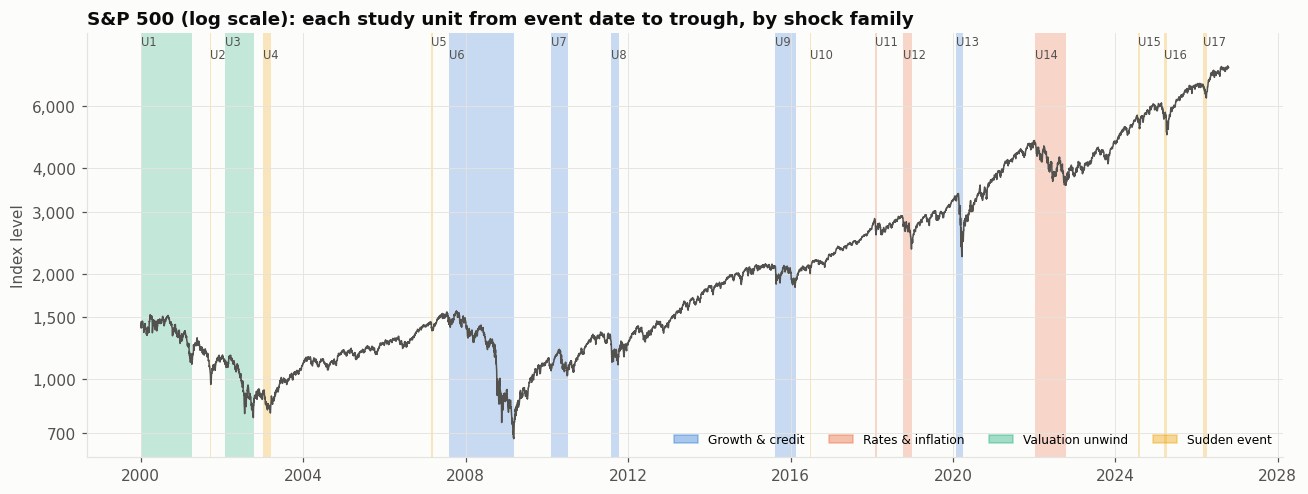

In [1043]:
# Figure 1: S&P 500 with study units shaded
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(d.index, d.close, color=INK2, lw=1)
ax.set_yscale("log")
ax.set_yticks([700, 1000, 1500, 2000, 3000, 4000, 6000])
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.minorticks_off()
ymax = d.close.max() * 1.15
for i, u in units.iterrows():
    a = pd.Timestamp(u.event_date)
    b = pd.Timestamp(u.event_trough) + pd.Timedelta(days=5)
    ax.axvspan(a, b, color=FAMILY_STYLE[u.family][0], alpha=0.25, lw=0)
    ax.text(a, ymax * (0.92 if i % 2 else 1.0), u.code, fontsize=7.5, color=INK2)
handles = [matplotlib.patches.Patch(color=c, alpha=0.4, label=fam) for fam, (c, _) in FAMILY_STYLE.items()]
ax.legend(handles=handles, loc="lower right", ncol=4, fontsize=8)
ax.set_ylim(top=ymax * 1.08)
ax.set_title("S&P 500 (log scale): each study unit from event date to trough, by shock family")
ax.set_ylabel("Index level")
fig.tight_layout(); fig.savefig(FIG / "fig01_sp500_study_units.png"); plt.show()

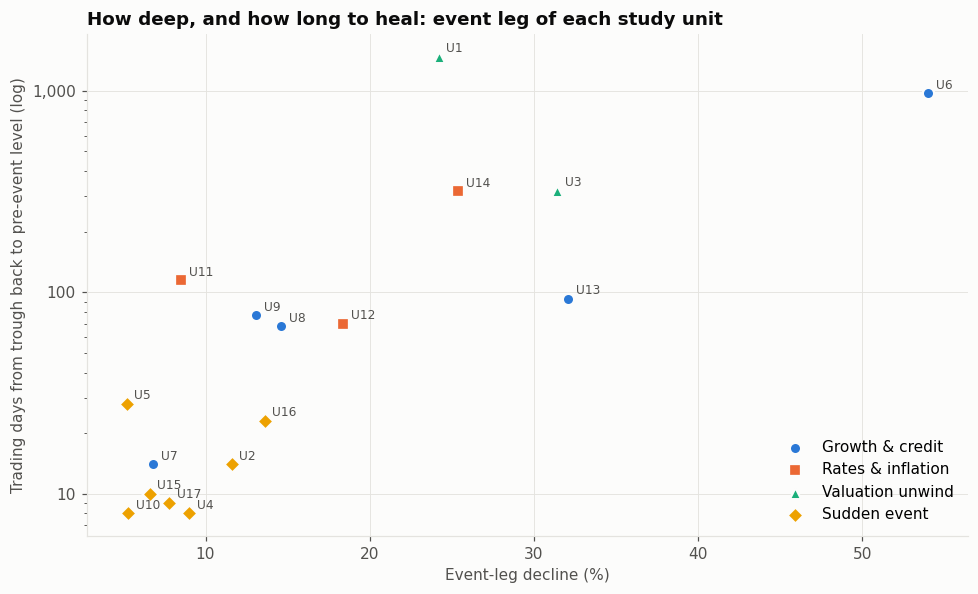

In [1044]:
# Figure 2: depth vs time to recover (event leg), coloured and shaped by family
fig, ax = plt.subplots(figsize=(9, 5.5))
r = units.copy()
r["rec"] = pd.to_numeric(r.event_days_to_recover, errors="coerce")
for fam, (c, m) in FAMILY_STYLE.items():
    s = r[(r.family == fam) & r.rec.notna()]
    ax.scatter(-s.event_depth_pct, s.rec.clip(lower=1), s=55, color=c, marker=m,
               edgecolor=SURFACE, linewidth=1.5, label=fam, zorder=3)
for _, row in r[r.rec.notna()].iterrows():
    ax.annotate(row.code, (-row.event_depth_pct, max(row.rec, 1)), fontsize=8, color=INK2,
                xytext=(5, 3), textcoords="offset points")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Event-leg decline (%)")
ax.set_ylabel("Trading days from trough back to pre-event level (log)")
ax.set_title("How deep, and how long to heal: event leg of each study unit")
ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "fig02_depth_vs_recovery.png"); plt.show()
if r.rec.isna().any():
    print("Not yet recovered (not plotted):", list(r.loc[r.rec.isna(), "unit"]))

## 10b. Is it the type of shock, or just the size of the fall?
**Why this matters.** Families differ in depth as well as type: valuation unwinds fell further than sudden events. A slower recovery might simply reflect a deeper fall. To separate the two, the log of recovery time is regressed on the log of the event-leg decline plus family indicators (sudden events = baseline):

$$\ln(\text{days to recover}_i) = \alpha + \beta \ln|\text{decline}_i| + \sum_f \gamma_f\, \mathbf{1}[\text{family}_i = f] + \varepsilon_i$$

With 17 crises, standard errors are unreliable, so significance comes from **permutation tests**: (1) family labels are shuffled 20,000 times and the F-statistic for the family terms is recomputed; (2) a Freedman–Lane test shuffles the residuals of the depth-only model, which keeps the depth–recovery link intact and is the standard valid test of whether family adds explanatory power beyond depth. The test is then repeated dropping each crisis in turn. Results are exploratory.

In [1046]:
def ols_ss(y, X):
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    return b, float(((y - X @ b) ** 2).sum())

def family_test(df, n_perm=20000, seed=0):
    y = np.log(df.event_days_to_recover.values.astype(float))
    ld = np.log(-df.event_depth_pct.values.astype(float))
    fam_ = df.family.values
    levels = [f for f in ["Growth & credit", "Rates & inflation", "Valuation unwind"] if (fam_ == f).any()]
    D = lambda f: np.column_stack([(f == k).astype(float) for k in levels])
    one = np.ones(len(y))
    _, ss_d = ols_ss(y, np.column_stack([one, ld]))
    _, ss_f = ols_ss(y, np.column_stack([one, D(fam_)]))
    b, ss_full = ols_ss(y, np.column_stack([one, ld, D(fam_)]))
    q, dfe = len(levels), len(y) - 2 - len(levels)
    F = ((ss_d - ss_full) / q) / (ss_full / dfe)
    rng = np.random.default_rng(seed)
    hits = sum(((ss_d - s) / q) / (s / dfe) >= F
               for s in (ols_ss(y, np.column_stack([one, ld, D(rng.permutation(fam_))]))[1] for _ in range(n_perm)))
    # Freedman-Lane residual permutation: shuffle the residuals of the depth-only model, which keeps
    # the depth-recovery relationship intact and tests whether family adds anything beyond depth
    Xd, Xf = np.column_stack([one, ld]), np.column_stack([one, ld, D(fam_)])
    bd, _ = ols_ss(y, Xd); fit_d = Xd @ bd; e_d = y - fit_d
    def F_of(yy):
        s0 = ols_ss(yy, Xd)[1]; s1 = ols_ss(yy, Xf)[1]
        return ((s0 - s1) / q) / (s1 / dfe)
    hits_fl = sum(F_of(fit_d + rng.permutation(e_d)) >= F for _ in range(n_perm))
    tss = ((y - y.mean()) ** 2).sum()
    return {"r2_depth": 1 - ss_d / tss, "r2_family": 1 - ss_f / tss, "r2_both": 1 - ss_full / tss,
            "depth_coef": b[1], "F_family": F, "p_perm": hits / n_perm, "p_freedman_lane": hits_fl / n_perm,
            **{f"x_{k}": np.exp(v) for k, v in zip(levels, b[2:])}}

reg_df = units.dropna(subset=["event_days_to_recover"])
reg_df = reg_df[(reg_df.event_depth_pct < 0) & (reg_df.event_days_to_recover > 0)]
reg = family_test(reg_df)
print(f"R-squared: depth only {reg['r2_depth']:.2f} | family only {reg['r2_family']:.2f} | both {reg['r2_both']:.2f}")
print(f"Elasticity of recovery time to depth (given family): {reg['depth_coef']:.2f}")
print(f"Family terms given depth: F = {reg['F_family']:.2f}, label-permutation p = {reg['p_perm']:.3f}, "
      f"Freedman-Lane residual-permutation p = {reg['p_freedman_lane']:.3f}")
print("Recovery time relative to a sudden event of the SAME depth:")
for k in ["Growth & credit", "Rates & inflation", "Valuation unwind"]:
    if f"x_{k}" in reg:
        print(f"  {k}: x{reg[f'x_{k}']:.1f}")
loo_all = pd.DataFrame({c: family_test(reg_df[reg_df.code != c], n_perm=5000, seed=1) for c in reg_df.code}).T
loo_p = loo_all["p_perm"].rename("p_perm_without_this_crisis")
loo_fl = loo_all["p_freedman_lane"]
print(f"Leave-one-crisis-out Freedman-Lane p: min {loo_fl.min():.3f}, max {loo_fl.max():.3f}, "
      f"below 0.05 in {(loo_fl < 0.05).sum()} of {len(loo_fl)}")
print(f"Leave-one-crisis-out permutation p: min {loo_p.min():.3f}, max {loo_p.max():.3f}, "
      f"below 0.05 in {(loo_p < 0.05).sum()} of {len(loo_p)}, below 0.10 in {(loo_p < 0.10).sum()} of {len(loo_p)}")
pd.Series(reg).to_frame("full_sample").T.to_csv(OUT / "depth_controlled_recovery.csv")
loo_p.to_csv(OUT / "depth_controlled_recovery_loo.csv")

R-squared: depth only 0.68 | family only 0.71 | both 0.84
Elasticity of recovery time to depth (given family): 1.20
Family terms given depth: F = 4.07, label-permutation p = 0.035, Freedman-Lane residual-permutation p = 0.035
Recovery time relative to a sudden event of the SAME depth:
  Growth & credit: x2.6
  Rates & inflation: x4.7
  Valuation unwind: x12.2
Leave-one-crisis-out Freedman-Lane p: min 0.009, max 0.095, below 0.05 in 7 of 17
Leave-one-crisis-out permutation p: min 0.009, max 0.094, below 0.05 in 6 of 17, below 0.10 in 17 of 17


---
# PART 2: UNDERSTANDING THE MARKET'S BEHAVIOR

## 11. Event windows
Part 2 looks at what *else* happened while stocks fell. Every unit is split into two phases:

- **Fall:** from the event-leg base (last close before the event) to the S&P 500 event-leg trough.
- **Rebound:** from the trough to 60 trading days later.

Returns are total returns for funds and ETFs. Yields, credit spreads and the VIX are reported as changes. A blank means the series did not exist yet (gold, oil before Aug 2000).

In [1048]:
def at(series, date):
    s = series.loc[:pd.Timestamp(date)].dropna()
    return s.iloc[-1] if len(s) else np.nan

def pct(col, a, b):
    if col not in prices:
        return np.nan
    pa, pb = prices[col].get(pd.Timestamp(a), np.nan), prices[col].get(pd.Timestamp(b), np.nan)
    return 100 * (pb / pa - 1) if pd.notna(pa) and pd.notna(pb) else np.nan

win = units[["unit", "code", "family", "event_base_date", "event_trough"]].copy()
win["rebound_end"] = [px.index[min(loc(pd.Timestamp(t)) + CONFIG["rebound_days"], len(px) - 1)].date()
                      for t in win.event_trough]
win["fall_days"] = [loc(pd.Timestamp(t)) - loc(pd.Timestamp(b)) for b, t in zip(win.event_base_date, win.event_trough)]

ASSET_LIST = [a for a in CROSS_ASSETS + SECTORS if a in prices]
fall = pd.DataFrame({a: [pct(a, b, t) for b, t in zip(win.event_base_date, win.event_trough)]
                     for a in ASSET_LIST}, index=win.code)
rebound = pd.DataFrame({a: [pct(a, t, e) for t, e in zip(win.event_trough, win.rebound_end)]
                        for a in ASSET_LIST}, index=win.code)

def change(col, a, b, scale=1.0):
    if col in prices:
        return scale * (prices[col].get(pd.Timestamp(b), np.nan) - prices[col].get(pd.Timestamp(a), np.nan))
    return np.nan

rates = pd.DataFrame({
    "ust10y_bp": [change("ust10y", b, t, 100) for b, t in zip(win.event_base_date, win.event_trough)],
    "ust3m_bp": [change("ust3m", b, t, 100) for b, t in zip(win.event_base_date, win.event_trough)],
    "vix_before": [prices["vix"].get(pd.Timestamp(b), np.nan) if "vix" in prices else np.nan for b in win.event_base_date],
    "vix_peak": [prices["vix"].loc[pd.Timestamp(b):pd.Timestamp(t)].max() if "vix" in prices else np.nan
                 for b, t in zip(win.event_base_date, win.event_trough)],
    "credit_spread_bp": [100 * (at(fred["credit_spread"], t) - at(fred["credit_spread"], b))
                         if "credit_spread" in fred else np.nan
                         for b, t in zip(win.event_base_date, win.event_trough)],
}, index=win.code)

behaviour = win.set_index("code").join(fall.add_suffix("_fall")).join(rates).join(rebound.add_suffix("_rebound"))
behaviour.to_csv(OUT / "cross_asset_behaviour.csv")
print("FALL PHASE: total return (%) from event base to S&P trough, plus rate / fear moves")
display(win.set_index("code")[["unit", "family", "fall_days"]].join(fall[[a for a in CROSS_ASSETS if a in fall]]).join(rates).round(1))

FALL PHASE: total return (%) from event base to S&P trough, plus rate / fear moves


,unit,family,fall_days,sp500_tr,int_tsy,long_tsy,gold,oil,dollar,ust10y_bp,ust3m_bp,vix_before,vix_peak,credit_spread_bp
code,,,,,,,,,,,,,,
U1,U1 Dot-com bust,Valuation unwind,316,-23.10,18.50,22.70,NaN,NaN,14.80,-162.50,-127.00,24.20,34.70,135.00
U2,U2 9/11,Sudden event,5,-11.60,1.30,-0.80,7.50,-6.00,-1.30,-14.60,-98.00,31.80,43.70,54.00
U3,U3 Accounting-scandal bear market,Valuation unwind,177,-30.70,13.70,16.40,14.80,46.40,-10.90,-149.90,-16.20,21.10,45.10,112.00
U4,U4 Iraq war,Sudden event,47,-8.70,1.90,3.20,0.80,17.70,-3.80,-23.20,-12.00,28.60,34.70,-20.00
U5,U5 China Feb 2007,Sudden event,5,-5.20,1.00,1.30,-7.30,-2.20,0.30,-11.30,-8.50,11.10,19.60,14.00
U6,U6 Global financial crisis,Growth & credit,402,-52.30,18.70,21.80,38.10,-38.80,10.30,-186.70,-454.50,21.20,80.90,357.00
U7,U7 Euro crisis 2010,Growth & credit,104,-6.10,5.00,11.30,8.60,-6.30,6.40,-72.40,7.00,21.60,45.80,46.00
U8,U8 US downgrade and euro crisis 2011,Growth & credit,44,-14.30,3.70,21.50,2.30,-18.20,7.00,-95.50,-5.50,23.70,48.00,54.00
U9,U9 China 2015-16,Growth & credit,128,-12.10,3.90,9.50,13.00,-41.70,-1.60,-59.40,20.80,12.20,40.70,70.00


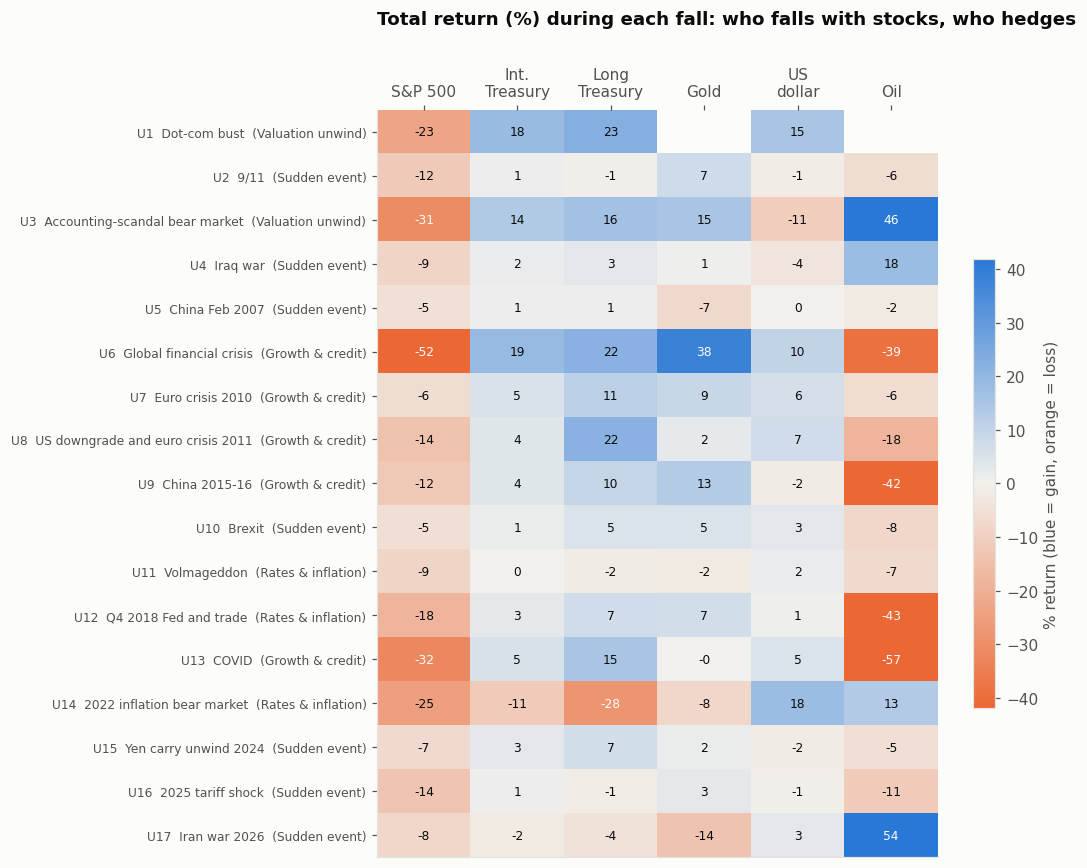

In [1049]:
# Figure 3: cross-asset heat map during the fall
cols = [a for a in ["sp500_tr", "int_tsy", "long_tsy", "gold", "dollar", "oil"] if a in fall]
nice = {"sp500_tr": "S&P 500", "int_tsy": "Int.\nTreasury", "long_tsy": "Long\nTreasury",
        "gold": "Gold", "dollar": "US\ndollar", "oil": "Oil"}
mat = fall[cols]
labels_y = [f"{c}  {units.set_index('code').loc[c, 'unit'].split(' ', 1)[1]}  ({units.set_index('code').loc[c, 'family']})"
            for c in mat.index]
lim = np.nanpercentile(np.abs(mat.values), 95)
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(mat.values, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(cols)), [nice[c] for c in cols])
ax.set_yticks(range(len(mat)), labels_y, fontsize=8)
ax.grid(False)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        ax.text(j, i, "" if np.isnan(v) else f"{v:.0f}", ha="center", va="center", fontsize=8,
                color=INK if abs(v) < 0.6 * lim else SURFACE)
ax.xaxis.tick_top()
ax.set_title("Total return (%) during each fall: who falls with stocks, who hedges", pad=28)
fig.colorbar(im, ax=ax, shrink=0.6, label="% return (blue = gain, orange = loss)")
fig.tight_layout(); fig.savefig(FIG / "fig03_cross_asset_heatmap.png"); plt.show()

## 12. Speed of the fall and the fear gauge
**Intuition.** Sudden-event shocks should be *fast* (days) with a VIX spike out of proportion to the price damage, because they are mostly a jump in the risk premium. Growth and credit crises should be *slow and deep*, because profits and balance sheets are being repriced week by week. Valuation unwinds should be the slowest, a grinding de-rating rather than a panic.

In [1051]:
speed = (units[["code", "family", "event_depth_pct", "event_days_to_trough", "event_days_to_recover"]]
         .set_index("code").join(rates[["vix_before", "vix_peak"]]))
speed["vix_jump"] = speed.vix_peak - speed.vix_before
speed["vix_jump_per_1pct_fall"] = speed.vix_jump / (-speed.event_depth_pct).replace(0, np.nan)
speed["fall_per_day_pct"] = speed.event_depth_pct / speed.event_days_to_trough.replace(0, np.nan)
display(speed.round(2))
print("Medians by family:")
display(speed.groupby("family")[["event_depth_pct", "event_days_to_trough", "fall_per_day_pct",
                                 "vix_jump", "vix_jump_per_1pct_fall", "event_days_to_recover"]].median().round(2))

,family,event_depth_pct,event_days_to_trough,event_days_to_recover,vix_before,vix_peak,vix_jump,vix_jump_per_1pct_fall,fall_per_day_pct
code,,,,,,,,,
U1,Valuation unwind,-24.20,316,1472,24.21,34.72,10.51,0.43,-0.08
U2,Sudden event,-11.60,5,14,31.84,43.74,11.90,1.03,-2.32
U3,Valuation unwind,-31.40,177,320,21.14,45.08,23.94,0.76,-0.18
U4,Sudden event,-9.00,47,8,28.62,34.69,6.07,0.67,-0.19
U5,Sudden event,-5.20,5,28,11.15,19.63,8.48,1.63,-1.04
U6,Growth & credit,-54.00,402,971,21.22,80.86,59.64,1.10,-0.13
U7,Growth & credit,-6.80,104,14,21.60,45.79,24.19,3.56,-0.07
U8,Growth & credit,-14.60,44,68,23.66,48.00,24.34,1.67,-0.33
U9,Growth & credit,-13.10,128,77,12.23,40.74,28.51,2.18,-0.10


Medians by family:


,event_depth_pct,event_days_to_trough,fall_per_day_pct,vix_jump,vix_jump_per_1pct_fall,event_days_to_recover
family,,,,,,
Growth & credit,-14.60,104.00,-0.13,28.51,2.12,77.00
Rates & inflation,-18.40,52.00,-0.35,20.12,1.09,115.00
Sudden event,-7.80,9.00,-0.73,11.19,1.61,10.00
Valuation unwind,-27.80,246.50,-0.13,17.23,0.60,896.00


## 13. Who hedges? Stocks, bonds, gold and the dollar
**Intuition (H2).** Treasuries are a hedge only when stocks fall *because growth is collapsing*: investors flee to safety and the Fed is expected to cut, so yields fall and bond prices rise. When stocks fall *because rates are rising*, bonds are the cause, not the cure, and both fall together. Gold and the dollar are "fear assets", but the dollar can also fall when the shock originates in U.S. policy.

Three views:
1. Did each hedge asset gain while stocks fell? (share of units, by family)
2. Daily stock-bond correlation *inside* each fall window.
3. Rolling 1-year stock-bond correlation over the whole sample: the regime the shock arrives in.

In [1053]:
hedges = [a for a in ["int_tsy", "long_tsy", "gold", "dollar"] if a in fall]
hedge_tbl = fall[hedges].join(units.set_index("code")[["family"]])
summary_rows = []
for fam, g in hedge_tbl.groupby("family"):
    row = {"family": fam, "units": len(g)}
    for a in hedges:
        v = g[a].dropna()
        row[f"{a}_median_%"] = v.median() if len(v) else np.nan
        row[f"{a}_gained"] = f"{int((v > 0).sum())}/{len(v)}"
    summary_rows.append(row)
hedge_summary = pd.DataFrame(summary_rows).set_index("family")
hedge_summary.to_csv(OUT / "hedge_summary_by_family.csv")

# Fisher exact test: did intermediate Treasuries gain less often in rate shocks than in other crises?
from math import comb
def fisher_less(a, b, c, d):        # P(rate-shock gains <= a) given the margins of [[a, b], [c, d]]
    n, r1, c1 = a + b + c + d, a + b, a + c
    return sum(comb(c1, k) * comb(n - c1, r1 - k) / comb(n, r1) for k in range(0, a + 1))
if "int_tsy" in fall:
    gained = (hedge_tbl.int_tsy > 0)
    is_rate = hedge_tbl.family == "Rates & inflation"
    a, b = int(gained[is_rate].sum()), int((~gained[is_rate]).sum())
    c, d_ = int(gained[~is_rate].sum()), int((~gained[~is_rate]).sum())
    fisher_p = fisher_less(a, b, c, d_)
    print(f"Treasuries gained in {a}/{a + b} rate shocks vs {c}/{c + d_} other crises; "
          f"Fisher exact one-sided p = {fisher_p:.3f}")
display(hedge_summary.round(1))

# daily stock-bond correlation inside each fall window
dr = prices[[c for c in ["sp500_tr", "int_tsy", "long_tsy", "gold"] if c in prices]].pct_change()
corr_rows = []
for _, w in win.iterrows():
    seg = dr.loc[pd.Timestamp(w.event_base_date):pd.Timestamp(w.event_trough)].dropna(subset=["sp500_tr"])
    ok = len(seg) >= 10
    corr_rows.append({"code": w.code, "family": w.family, "days": len(seg),
                      "corr_stock_int_tsy": seg.sp500_tr.corr(seg.int_tsy) if ok and "int_tsy" in seg else np.nan,
                      "corr_stock_gold": seg.sp500_tr.corr(seg.gold) if ok and "gold" in seg else np.nan})
window_corr = pd.DataFrame(corr_rows).set_index("code")
print("Daily correlation inside each fall window (needs >= 10 days):")
display(window_corr.round(2))
display(window_corr.groupby("family")[["corr_stock_int_tsy", "corr_stock_gold"]].median().round(2))

Treasuries gained in 1/3 rate shocks vs 13/14 other crises; Fisher exact one-sided p = 0.063


,units,int_tsy_median_%,int_tsy_gained,long_tsy_median_%,long_tsy_gained,gold_median_%,gold_gained,dollar_median_%,dollar_gained
family,,,,,,,,,
Growth & credit,5,5.00,5/5,14.70,5/5,8.60,4/5,6.40,4/5
Rates & inflation,3,0.00,1/3,-1.70,1/3,-2.00,1/3,1.80,3/3
Sudden event,7,1.30,6/7,1.30,4/7,1.50,5/7,-0.80,3/7
Valuation unwind,2,16.10,2/2,19.50,2/2,14.80,1/1,2.00,1/2


Daily correlation inside each fall window (needs >= 10 days):


,family,days,corr_stock_int_tsy,corr_stock_gold
code,,,,
U1,Valuation unwind,317,-0.20,-0.09
U2,Sudden event,6,NaN,NaN
U3,Valuation unwind,178,-0.49,-0.22
U4,Sudden event,48,-0.54,-0.38
U5,Sudden event,6,NaN,NaN
U6,Growth & credit,403,-0.48,-0.05
U7,Growth & credit,105,-0.69,0.10
U8,Growth & credit,45,-0.67,-0.31
U9,Growth & credit,129,-0.42,-0.11


,corr_stock_int_tsy,corr_stock_gold
family,,
Growth & credit,-0.61,-0.05
Rates & inflation,-0.17,-0.04
Sudden event,-0.12,0.16
Valuation unwind,-0.34,-0.16


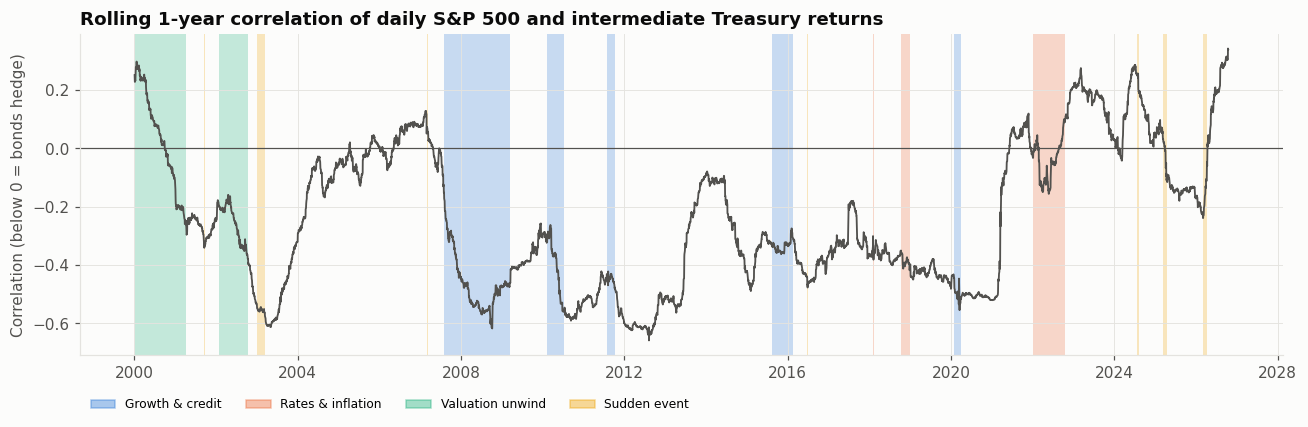

In [1054]:
# Figure 4: rolling 1-year stock-bond correlation, study units marked
n = CONFIG["rolling_corr_days"]
roll = dr.sp500_tr.rolling(n).corr(dr.int_tsy).loc[CONFIG["analysis_start"]:]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(roll.index, roll, color=INK2, lw=1.2)
ax.axhline(0, color=INK2, lw=0.8)
for _, u in units.iterrows():
    ax.axvspan(pd.Timestamp(u.event_date), pd.Timestamp(u.event_trough) + pd.Timedelta(days=5),
               color=FAMILY_STYLE[u.family][0], alpha=0.25, lw=0)
handles = [matplotlib.patches.Patch(color=c, alpha=0.4, label=fam) for fam, (c, _) in FAMILY_STYLE.items()]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0, -0.1), ncol=4, fontsize=8)
ax.set_title("Rolling 1-year correlation of daily S&P 500 and intermediate Treasury returns")
ax.set_ylabel("Correlation (below 0 = bonds hedge)")
fig.tight_layout(); fig.savefig(FIG / "fig04_rolling_stock_bond_corr.png"); plt.show()

## 14. Sector rotation: who leads the fall and who leads the rebound
**Intuition (H3).** Defensive sectors (staples, health care, utilities) sell things people buy in any economy, so their profits barely move in a downturn: they should fall less. Cyclicals depend on the cycle and should lead the rebound. *Which* cyclical suffers most should reveal the shock's door: financials in a credit crisis, tech (long-duration cash flows) in a rate shock, energy in an oil or growth shock.

In [1056]:
sec = [s for s in SECTORS if s in fall]
dfn, cyc = [s for s in DEFENSIVE if s in sec], [s for s in CYCLICAL if s in sec]
rot = pd.DataFrame(index=fall.index)
rot["family"] = units.set_index("code").family
rot["defensive_fall"] = fall[dfn].mean(axis=1)
rot["cyclical_fall"] = fall[cyc].mean(axis=1)
rot["defensive_minus_cyclical_fall"] = rot.defensive_fall - rot.cyclical_fall
rot["cyclical_minus_defensive_rebound"] = rebound[cyc].mean(axis=1) - rebound[dfn].mean(axis=1)
rot["worst_sector_fall"] = fall[sec].idxmin(axis=1, skipna=True)
rot["best_sector_fall"] = fall[sec].idxmax(axis=1, skipna=True)
rot["best_sector_rebound"] = rebound[sec].idxmax(axis=1, skipna=True)
rot.to_csv(OUT / "sector_rotation.csv")
display(rot.round(1))
print("By family (medians, % points):")
display(rot.groupby("family")[["defensive_minus_cyclical_fall", "cyclical_minus_defensive_rebound"]].median().round(1))
print("Worst sector in the fall, counts by family:")
display(pd.crosstab(rot.family, rot.worst_sector_fall))

,family,defensive_fall,cyclical_fall,defensive_minus_cyclical_fall,cyclical_minus_defensive_rebound,worst_sector_fall,best_sector_fall,best_sector_rebound
code,,,,,,,,
U1,Valuation unwind,4.60,-13.10,17.60,8.00,tech,utilities,tech
U2,Sudden event,-8.20,-14.00,5.80,14.30,industrials,utilities,tech
U3,Valuation unwind,-22.00,-29.70,7.60,6.90,tech,health,tech
U4,Sudden event,-7.80,-9.10,1.30,6.00,materials,energy,cons_disc
U5,Sudden event,-4.30,-5.70,1.40,2.90,materials,staples,energy
U6,Growth & credit,-32.70,-56.50,23.80,32.00,financials,staples,financials
U7,Growth & credit,-5.80,-6.10,0.30,3.40,energy,cons_disc,materials
U8,Growth & credit,-4.10,-19.10,14.90,4.40,energy,utilities,energy
U9,Growth & credit,-3.60,-14.80,11.20,6.80,financials,utilities,energy


By family (medians, % points):


,defensive_minus_cyclical_fall,cyclical_minus_defensive_rebound
family,,
Growth & credit,11.20,6.80
Rates & inflation,4.60,4.30
Sudden event,4.90,6.90
Valuation unwind,12.60,7.40


Worst sector in the fall, counts by family:


worst_sector_fall,cons_disc,energy,financials,industrials,materials,tech
family,,,,,,
Growth & credit,0,3,2,0,0,0
Rates & inflation,1,2,0,0,0,0
Sudden event,0,0,1,2,2,2
Valuation unwind,0,0,0,0,0,2


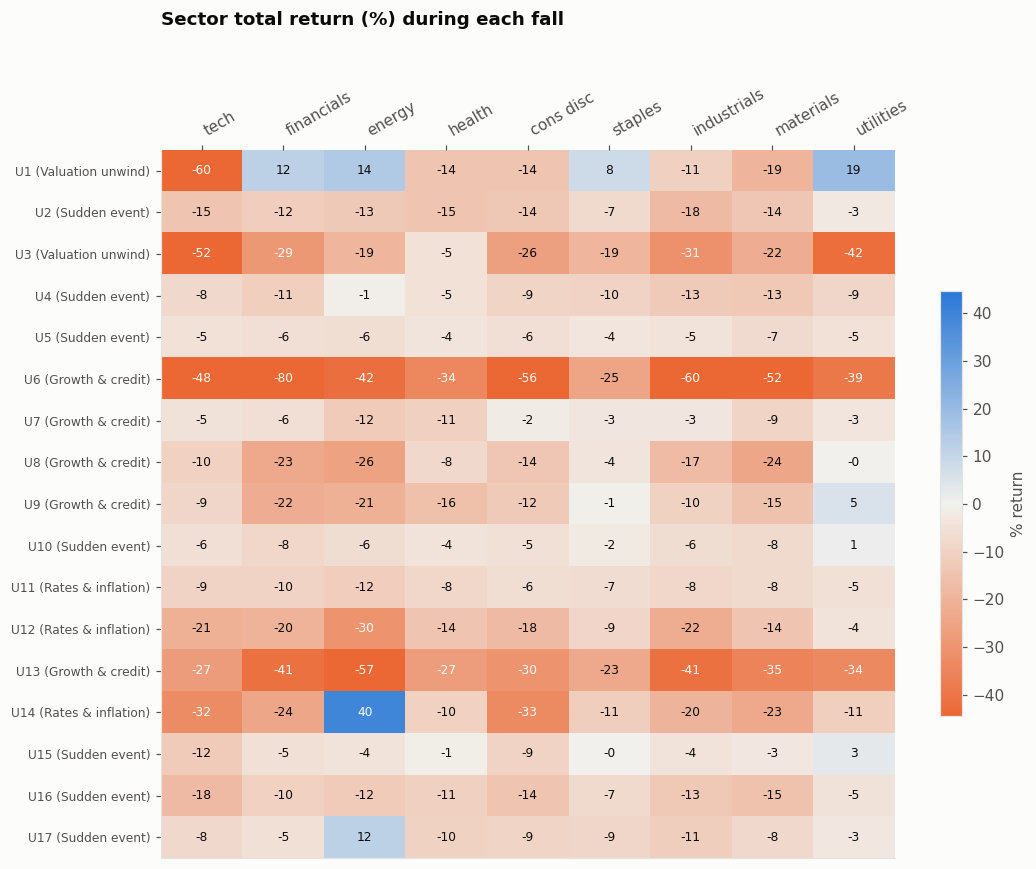

In [1057]:
# Figure 5: sector returns during the fall
mat = fall[sec]
lim = np.nanpercentile(np.abs(mat.values), 95)
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(mat.values, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(sec)), [s.replace("_", " ") for s in sec], rotation=30, ha="left")
ax.set_yticks(range(len(mat)), [f"{c} ({units.set_index('code').loc[c, 'family']})" for c in mat.index], fontsize=8)
ax.grid(False)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        ax.text(j, i, "" if np.isnan(v) else f"{v:.0f}", ha="center", va="center", fontsize=8,
                color=INK if abs(v) < 0.6 * lim else SURFACE)
ax.xaxis.tick_top()
ax.set_title("Sector total return (%) during each fall", pad=40)
fig.colorbar(im, ax=ax, shrink=0.6, label="% return")
fig.tight_layout(); fig.savefig(FIG / "fig05_sector_heatmap.png"); plt.show()

## 15. Starting conditions and policy response
**Intuition (H1, H4).** The same shock does different damage depending on where it lands and whether anyone can cushion it.

- **Starting conditions:** how calm the market was (VIX), how high rates were, the yield curve (inverted = recession risk already priced), how far stocks had run in the prior year, and (if FRED is available) credit spreads and inflation.
- **Policy response:** the change in the 3-month Treasury yield over the 6 months after the event. A large fall means the Fed cut hard; a rise means it was tightening into the shock.

If H4 holds, units where the Fed eased should recover faster than units where it could not.

In [1059]:
pol = pd.DataFrame(index=units.code)
pol["family"] = units.set_index("code").family
b_dates = units.set_index("code").event_base_date
pol["vix_before"] = rates.vix_before
pol["ust10y_before"] = [prices["ust10y"].get(pd.Timestamp(b), np.nan) if "ust10y" in prices else np.nan for b in b_dates]
pol["ust3m_before"] = [prices["ust3m"].get(pd.Timestamp(b), np.nan) if "ust3m" in prices else np.nan for b in b_dates]
pol["curve_10y_3m"] = pol.ust10y_before - pol.ust3m_before
pol["sp500_prior_12m_%"] = [100 * (px[pd.Timestamp(b)] / px.iloc[max(loc(pd.Timestamp(b)) - 252, 0)] - 1) for b in b_dates]
if "credit_spread" in fred:
    pol["credit_spread_before"] = [at(fred["credit_spread"], b) for b in b_dates]
if "cpi" in fred:
    cpi = fred["cpi"].dropna()
    pol["cpi_yoy_before_%"] = [100 * (at(cpi, b) / at(cpi, pd.Timestamp(b) - pd.DateOffset(years=1)) - 1) for b in b_dates]
pol["policy_3m_change_6m_bp"] = [
    100 * (prices["ust3m"].iloc[min(loc(pd.Timestamp(b)) + CONFIG["policy_window_days"], len(px) - 1)]
           - prices["ust3m"].get(pd.Timestamp(b), np.nan)) if "ust3m" in prices else np.nan for b in b_dates]
pol["fed_eased"] = pol.policy_3m_change_6m_bp < -50
pol["event_depth_pct"] = units.set_index("code").event_depth_pct
pol["event_days_to_recover"] = pd.to_numeric(units.set_index("code").event_days_to_recover, errors="coerce")
pol.to_csv(OUT / "macro_backdrop_policy.csv")
display(pol.round(2))
print("Recovery when the Fed eased (3-month yield down > 50bp in 6 months) vs not:")
display(pol.groupby("fed_eased")[["event_depth_pct", "event_days_to_recover"]]
        .agg(["median", "count"]).round(1))
num = pol.drop(columns=["family", "fed_eased"]).apply(pd.to_numeric, errors="coerce")
print("Rank correlation of starting conditions with depth and recovery time (17 units, descriptive only):")
display(num.corr(method="spearman")[["event_depth_pct", "event_days_to_recover"]]
        .drop(["event_depth_pct", "event_days_to_recover"]).round(2))

,family,vix_before,ust10y_before,ust3m_before,curve_10y_3m,sp500_prior_12m_%,credit_spread_before,cpi_yoy_before_%,policy_3m_change_6m_bp,fed_eased,event_depth_pct,event_days_to_recover
code,,,,,,,,,,,,
U1,Valuation unwind,24.21,6.55,5.27,1.28,18.49,1.69,2.79,60.00,False,-24.20,1472
U2,Sudden event,31.84,4.84,3.18,1.65,-26.90,2.99,2.59,-136.00,True,-11.60,14
U3,Valuation unwind,21.14,5.08,1.69,3.39,-15.63,2.78,1.20,-1.30,False,-31.40,320
U4,Sudden event,28.62,3.82,1.18,2.64,-23.37,3.48,2.48,-33.50,False,-9.00,8
U5,Sudden event,11.15,4.63,5.05,-0.41,12.55,1.54,2.42,-96.50,True,-5.20,28
U6,Growth & credit,21.22,4.75,4.74,0.01,15.84,1.83,1.90,-269.50,True,-54.00,971
U7,Growth & credit,21.60,3.70,0.09,3.61,30.86,2.58,2.15,5.50,False,-6.80,14
U8,Growth & credit,23.66,2.74,0.08,2.67,14.31,2.77,3.75,-2.00,False,-14.60,68
U9,Growth & credit,12.23,2.24,0.06,2.17,8.94,2.93,0.24,23.50,False,-13.10,77


Recovery when the Fed eased (3-month yield down > 50bp in 6 months) vs not:


event_depth_pct       event_days_to_recover      
                   median count                median count
fed_eased                                                  
False              -13.40    12                 69.00    12
True               -11.60     5                 28.00     5

Rank correlation of starting conditions with depth and recovery time (17 units, descriptive only):


,event_depth_pct,event_days_to_recover
vix_before,-0.20,-0.15
ust10y_before,-0.04,0.14
ust3m_before,0.03,0.10
curve_10y_3m,-0.07,-0.03
sp500_prior_12m_%,-0.15,0.33
credit_spread_before,-0.15,-0.25
cpi_yoy_before_%,-0.18,0.05
policy_3m_change_6m_bp,0.06,0.20


---
# PART 2: STRESS TESTING

## 16. Stress-test design
**Why stress-test by shock type?** A single "market crash" scenario assumes every crisis looks the same. Sections 11–15 show they do not: bonds rescue a 60/40 portfolio in a growth shock and sink it in an inflation shock. A useful stress test asks *which* crash a portfolio is exposed to.

**Portfolios tested** (weights in the configuration cell):

| Portfolio | Holdings | Exposure it represents |
|---|---|---|
| S&P 500 | 100% S&P 500 | The market itself |
| 60/40 | 60% S&P 500, 40% intermediate Treasuries | The classic balanced investor, relies on bonds hedging |
| Tech tilt | 50% S&P 500, 50% technology | Long-duration growth exposure |
| Defensive | Equal staples, health care, utilities | Low-cyclicality equities |
| Diversified | 40% S&P 500, 30% long Treasuries, 15% intermediate Treasuries, 15% gold | Multiple hedges |

**Portfolio convention.** Every method uses **buy-and-hold** from the start date (no rebalancing), so replay, scenario and VaR numbers are directly comparable.

**Four methods**, from most concrete to most forward-looking:

| Method | Question | Section |
|---|---|---|
| 1. Historical replay | What would each portfolio have lost in each real crisis, and how long until it recovered? | 17 |
| 2. Family scenarios + out-of-sample test | Typical and severe scenario for each shock family; would scenarios built before 2020 have predicted 2020–2026 losses? | 18 |
| 3. Calm vs stress risk | Do relationships measured in calm markets hold in crises? How badly does a standard Value-at-Risk understate losses? | 19 |
| 4. Reverse stress test | How big a crash of each type would it take to lose 20%? | 20 |
| 5. Loss attribution and recovery | Which holding caused or cushioned each loss? Did falling less mean recovering sooner? | 20b |
| 6. What-if scenarios | How do portfolios fare in plausible shocks beyond history (stagflation, oil shock, sell America, dash for cash)? | 20c |

In [1061]:
PORTS = {}
for name, w in CONFIG["portfolios"].items():
    miss = [a for a in w if a not in prices or prices[a].isna().all()]
    if miss:
        print(f"Skipping {name}: missing {miss}")
        continue
    assert abs(sum(w.values()) - 1) < 1e-9, name
    PORTS[name] = w
display(pd.DataFrame(PORTS).fillna(0).T.round(3))

# ONE CONVENTION THROUGHOUT: buy-and-hold from a start date, no rebalancing.
# Replay (17), scenarios (18: weighted sum of asset returns = buy-and-hold) and VaR volatility (19) all use it.
def portfolio_path(weights, start, horizon):
    # value of 1 invested at the close of `start`, held without rebalancing
    i0 = loc(pd.Timestamp(start))
    p = prices[list(weights)].iloc[max(i0, 0):i0 + horizon + 1]
    if p.iloc[0].isna().any():
        return None
    rel = p.ffill() / p.iloc[0]
    return (rel * pd.Series(weights)).sum(axis=1)

def portfolio_returns_before(weights, end, days):
    # daily returns of a buy-and-hold portfolio started `days` before `end` (for VaR volatility)
    i_end = loc(pd.Timestamp(end))
    path = portfolio_path(weights, px.index[max(i_end - days, 0)], days)
    return None if path is None else path.pct_change().dropna()

,sp500_tr,int_tsy,tech,staples,health,utilities,long_tsy,gold
S&P 500,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
60/40,0.60,0.40,0.00,0.00,0.00,0.00,0.00,0.00
Tech tilt,0.50,0.00,0.50,0.00,0.00,0.00,0.00,0.00
Defensive,0.00,0.00,0.00,0.33,0.33,0.33,0.00,0.00
Diversified,0.40,0.15,0.00,0.00,0.00,0.00,0.30,0.15


## 17. Method 1: historical replay
Each portfolio is bought at the close before each event and held. Three numbers per crisis:
- **Loss at the S&P trough**: the portfolio's return over the same window the S&P 500 fell.
- **Worst loss from start**: the portfolio's lowest value relative to what was invested, between the event and 60 trading days after the S&P trough.
- **Max drawdown**: the conventional measure, largest fall from a *running peak* within the same window. It exceeds the loss from start when the portfolio first rose (e.g. bonds rallying) before falling.
- **Days underwater**: trading days from the portfolio's lowest point back to its starting value. "> 5 yrs" = not recovered within 5 years (censored).

In [1063]:
rep_rows = []
for _, u in units.iterrows():
    for name, w in PORTS.items():
        path = portfolio_path(w, u.event_base_date, CONFIG["replay_horizon_days"])
        if path is None:
            rep_rows.append({"code": u.code, "family": u.family, "portfolio": name}); continue
        at_trough = 100 * (path.get(pd.Timestamp(u.event_trough), np.nan) - 1)
        crisis = path.loc[:pd.Timestamp(win.set_index("code").loc[u.code, "rebound_end"])]
        own_tr = crisis.idxmin()                      # portfolio's own trough, during this crisis only
        back = path.loc[own_tr:]
        rec = back[back >= 1.0]
        rep_rows.append({"code": u.code, "family": u.family, "portfolio": name,
                         "loss_at_sp_trough_%": at_trough,
                         "worst_loss_from_start_%": 100 * (crisis.min() - 1),
                         "max_drawdown_%": 100 * (crisis / crisis.cummax() - 1).min(),
                         "days_underwater": (loc(rec.index[0]) - loc(own_tr)) if len(rec) else np.nan,
                         "recovered_within_5y": bool(len(rec))})
replay = pd.DataFrame(rep_rows)
replay.to_csv(OUT / "stress_historical_replay.csv", index=False)

loss_tbl = replay.pivot(index="code", columns="portfolio", values="loss_at_sp_trough_%")[list(PORTS)].reindex(units.code)
dd_tbl = replay.pivot(index="code", columns="portfolio", values="worst_loss_from_start_%")[list(PORTS)].reindex(units.code)
mdd_tbl = replay.pivot(index="code", columns="portfolio", values="max_drawdown_%")[list(PORTS)].reindex(units.code)
uw_tbl = replay.pivot(index="code", columns="portfolio", values="days_underwater")[list(PORTS)].reindex(units.code)
fam = units.set_index("code").family
print("Loss (%) at the S&P 500 trough"); display(loss_tbl.join(fam).round(1))
print("Worst loss from start (%)"); display(dd_tbl.join(fam).round(1))
print("Max drawdown from running peak (%)"); display(mdd_tbl.join(fam).round(1))
print("Trading days underwater after the portfolio's own trough ('> 5 yrs' = not recovered within 5 years)")
uw_show = uw_tbl.astype(object).where(uw_tbl.notna() | dd_tbl.isna(), "> 5 yrs")
display(uw_show.where(dd_tbl.notna(), "no data").join(fam))
print("Median loss at the S&P trough, by family"); display(loss_tbl.join(fam).groupby("family").median().round(1))

Loss (%) at the S&P 500 trough


,S&P 500,60/40,Tech tilt,Defensive,Diversified,family
code,,,,,,
U1,-23.10,-6.50,-41.60,4.60,NaN,Valuation unwind
U2,-11.60,-6.40,-13.10,-8.20,-3.60,Sudden event
U3,-30.70,-12.90,-41.20,-22.00,-3.10,Valuation unwind
U4,-8.70,-4.40,-8.30,-7.80,-2.10,Sudden event
U5,-5.20,-2.70,-5.10,-4.30,-2.60,Sudden event
U6,-52.30,-23.90,-50.10,-32.70,-5.90,Growth & credit
U7,-6.10,-1.60,-5.40,-5.80,3.00,Growth & credit
U8,-14.30,-7.10,-12.20,-4.10,1.70,Growth & credit
U9,-12.10,-5.70,-10.40,-3.60,0.50,Growth & credit


Worst loss from start (%)


,S&P 500,60/40,Tech tilt,Defensive,Diversified,family
code,,,,,,
U1,-23.10,-6.50,-41.60,-11.90,NaN,Valuation unwind
U2,-11.60,-6.40,-13.10,-8.20,-3.60,Sudden event
U3,-30.70,-14.40,-41.20,-26.20,-6.50,Valuation unwind
U4,-8.70,-4.40,-8.30,-7.80,-2.50,Sudden event
U5,-5.20,-2.70,-5.10,-4.30,-2.60,Sudden event
U6,-52.30,-23.90,-50.10,-32.70,-9.40,Growth & credit
U7,-6.10,-1.90,-5.40,-5.80,-1.50,Growth & credit
U8,-14.30,-7.20,-12.60,-8.80,-2.30,Growth & credit
U9,-12.10,-6.40,-11.50,-8.20,-3.60,Growth & credit


Max drawdown from running peak (%)


,S&P 500,60/40,Tech tilt,Defensive,Diversified,family
code,,,,,,
U1,-27.00,-12.10,-47.20,-15.70,NaN,Valuation unwind
U2,-11.60,-6.40,-13.10,-8.20,-3.70,Sudden event
U3,-33.00,-16.20,-41.40,-30.80,-8.60,Valuation unwind
U4,-13.80,-7.30,-16.10,-12.30,-4.10,Sudden event
U5,-5.20,-2.70,-5.10,-4.30,-2.60,Sudden event
U6,-55.30,-27.30,-53.70,-39.30,-17.40,Growth & credit
U7,-15.70,-7.90,-15.50,-9.20,-2.80,Growth & credit
U8,-14.30,-7.20,-12.60,-8.80,-3.20,Growth & credit
U9,-12.70,-6.50,-12.50,-9.30,-4.30,Growth & credit


Trading days underwater after the portfolio's own trough ('> 5 yrs' = not recovered within 5 years)


,S&P 500,60/40,Tech tilt,Defensive,Diversified,family
code,,,,,,
U1,> 5 yrs,21.00,> 5 yrs,27.00,no data,Valuation unwind
U2,14.00,8.00,14.00,45.00,5.00,Sudden event
U3,307.00,217.00,540.00,377.00,22.00,Valuation unwind
U4,8.00,8.00,4.00,8.00,45.00,Sudden event
U5,25.00,22.00,28.00,13.00,29.00,Sudden event
U6,540.00,274.00,469.00,391.00,23.00,Growth & credit
U7,6.00,5.00,6.00,15.00,3.00,Growth & credit
U8,18.00,57.00,48.00,14.00,4.00,Growth & credit
U9,42.00,45.00,42.00,87.00,36.00,Growth & credit


Median loss at the S&P trough, by family


,S&P 500,60/40,Tech tilt,Defensive,Diversified
family,,,,,
Growth & credit,-14.30,-7.10,-12.20,-5.80,0.50
Rates & inflation,-18.10,-9.70,-19.40,-9.10,-4.20
Sudden event,-7.70,-4.40,-8.30,-7.20,-2.60
Valuation unwind,-26.90,-9.70,-41.40,-8.70,-3.10


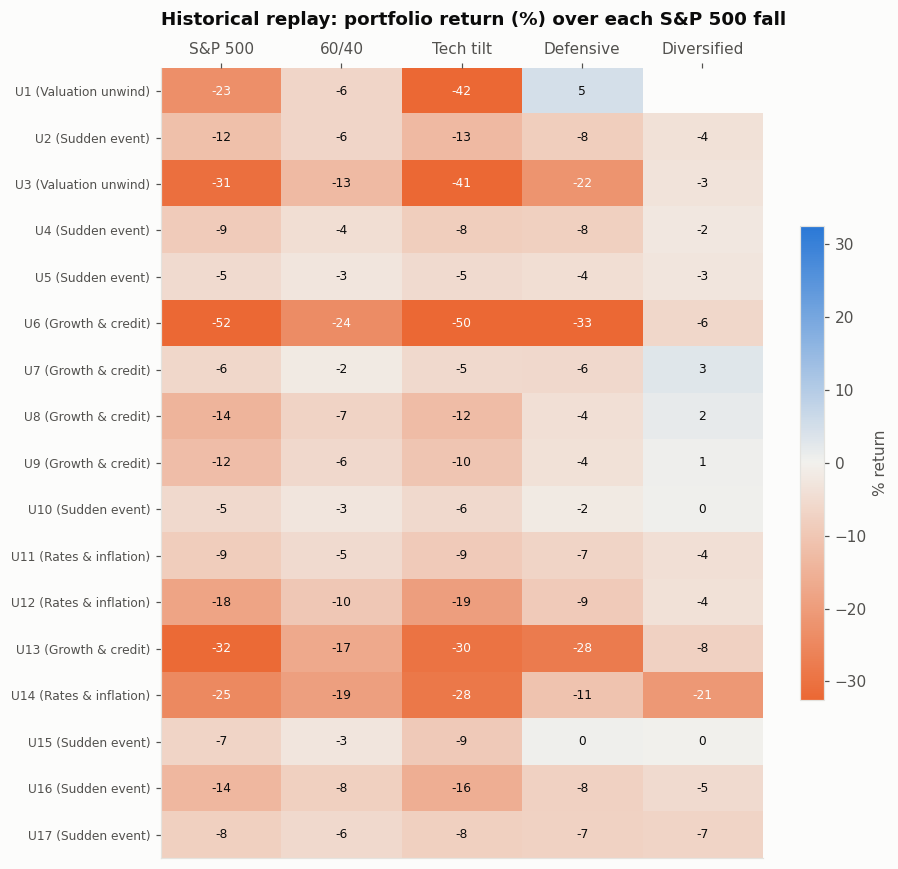

In [1064]:
# Figure 6: replay loss heat map, portfolios x crises
mat = loss_tbl
lim = np.nanpercentile(np.abs(mat.values), 95)
fig, ax = plt.subplots(figsize=(8.5, 8))
im = ax.imshow(mat.values, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(mat.shape[1]), mat.columns)
ax.set_yticks(range(len(mat)), [f"{c} ({fam[c]})" for c in mat.index], fontsize=8)
ax.grid(False)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        ax.text(j, i, "" if np.isnan(v) else f"{v:.0f}", ha="center", va="center", fontsize=8,
                color=INK if abs(v) < 0.6 * lim else SURFACE)
ax.xaxis.tick_top()
ax.set_title("Historical replay: portfolio return (%) over each S&P 500 fall", pad=28)
fig.colorbar(im, ax=ax, shrink=0.6, label="% return")
fig.tight_layout(); fig.savefig(FIG / "fig06_stress_replay.png"); plt.show()

## 18. Method 2: family scenarios and an out-of-sample test
For each shock family, two scenarios are built from the asset moves in Section 11:
- **Typical**: the median move of each asset across the family's crises.
- **Severe**: a full replay of the family's worst crisis (the one with the deepest S&P fall). Using one real crisis keeps the asset moves consistent with each other, which per-asset worst cases would not.

**Out-of-sample test (H5).** Scenarios are rebuilt using **only crises before 2020**, then used to predict the losses of the five later crises (COVID, 2022, yen carry, tariffs, Iran war). The benchmark is a *generic* crash scenario: the median of all pre-2020 crises regardless of type. If shock types matter, the family scenario should predict better.

Two versions of the test:
1. **Level test**: predict the loss outright. This mixes two questions: *how deep* the crisis was (which no scenario can know) and *how each portfolio behaved relative to the market*.
2. **Conditional test** (depth given): each portfolio's "crisis beta" (its loss per 1% fall in the S&P 500) is taken from pre-2020 crises and multiplied by the *actual* S&P fall. Because the actual fall is only known afterwards, this is **not a forecast**: it is a conditional stress-test validation that asks, *given* a crash of this size, does knowing the shock type tell you how each portfolio behaves?

**What would be known in real time?** The *family* of a shock can usually be named on the event date from the news (a bank failure, a pandemic, a tariff announcement, a war). The *depth, trough and recovery* cannot; they come from the historical windows of Part 1. So only the level test resembles a real-time stress test, and only if the family label is taken as known at the start. Section 18b repeats both tests with stricter, crisis-by-crisis designs.

In [1066]:
def scenario_loss(weights, moves):
    vals = [moves.get(a, np.nan) for a in weights]
    return np.nan if any(pd.isna(vals)) else float(sum(w * v for w, v in zip(weights.values(), vals)))

assets_needed = sorted({a for w in PORTS.values() for a in w} | {"sp500_tr"})
fall_f = fall[[a for a in assets_needed if a in fall]].join(fam)

scen_rows = []
for f_name, g in fall_f.groupby("family"):
    typical = g.drop(columns="family").median()
    worst_code = g.sp500_tr.idxmin()
    severe = g.drop(columns="family").loc[worst_code]
    for kind, mv, src in (("Typical", typical, f"median of {len(g)}"), ("Severe", severe, worst_code)):
        row = {"family": f_name, "scenario": kind, "based_on": src, "S&P 500 move": mv["sp500_tr"]}
        row.update({p: scenario_loss(w, mv) for p, w in PORTS.items()})
        scen_rows.append(row)
scenarios = pd.DataFrame(scen_rows)
scenarios.to_csv(OUT / "stress_family_scenarios.csv", index=False)
display(scenarios.round(1))

,family,scenario,based_on,S&P 500 move,S&P 500,60/40,Tech tilt,Defensive,Diversified
0,Growth & credit,Typical,median of 5,-14.30,-14.30,-6.60,-12.20,-7.80,0.80
1,Growth & credit,Severe,U6,-52.30,-52.30,-23.90,-50.10,-32.70,-5.90
2,Rates & inflation,Typical,median of 3,-18.10,-18.10,-10.80,-19.40,-8.30,-8.00
3,Rates & inflation,Severe,U14,-24.50,-24.50,-19.20,-28.50,-10.90,-21.00
4,Sudden event,Typical,median of 7,-7.70,-7.70,-4.10,-7.80,-5.20,-2.30
5,Sudden event,Severe,U16,-13.60,-13.60,-7.70,-15.60,-7.60,-5.30
6,Valuation unwind,Typical,median of 2,-26.90,-26.90,-9.70,-41.40,-8.70,-0.30
7,Valuation unwind,Severe,U3,-30.70,-30.70,-12.90,-41.20,-22.00,-3.10


In [1067]:
split = pd.Timestamp(CONFIG["oos_split_date"])
is_train = pd.to_datetime(units.set_index("code").event_date) < split
train = fall_f[is_train.reindex(fall_f.index).values]
test_codes = list(fall_f.index[~is_train.reindex(fall_f.index).values])

generic = train.drop(columns="family").median()
fam_typical = train.groupby("family").median(numeric_only=True)

oos_rows = []
for c in test_codes:
    f_name = fam[c]
    fam_mv = fam_typical.loc[f_name] if f_name in fam_typical.index else None
    for name, w in PORTS.items():
        oos_rows.append({"code": c, "family": f_name, "portfolio": name,
                         "actual_%": loss_tbl.loc[c, name],
                         "family_scenario_%": scenario_loss(w, fam_mv) if fam_mv is not None else np.nan,
                         "generic_scenario_%": scenario_loss(w, generic)})
oos = pd.DataFrame(oos_rows, columns=["code", "family", "portfolio", "actual_%",
                                      "family_scenario_%", "generic_scenario_%"])
if oos.empty:
    print("No crises after the split date: out-of-sample test skipped")
oos["family_error"] = oos["family_scenario_%"] - oos["actual_%"]
oos["generic_error"] = oos["generic_scenario_%"] - oos["actual_%"]
oos.to_csv(OUT / "stress_out_of_sample.csv", index=False)
display(oos.round(1))

mae = oos[["family_error", "generic_error"]].abs().mean()
print(f"Mean absolute error, family scenarios : {mae.family_error:.1f} pts")
print(f"Mean absolute error, generic scenario : {mae.generic_error:.1f} pts")
print("Note: predictions assume the typical depth; much of the error is the crisis being deeper or "
      "shallower than typical. The ranking of portfolios is checked next.")
rank_rows = []
for c, g in oos.groupby("code"):
    g = g.dropna(subset=["actual_%", "family_scenario_%", "generic_scenario_%"])
    if len(g) >= 3:
        rank_rows.append({"code": c,
                          "family_rank_corr": g["actual_%"].corr(g["family_scenario_%"], method="spearman"),
                          "generic_rank_corr": g["actual_%"].corr(g["generic_scenario_%"], method="spearman")})
if rank_rows:
    print("Does each scenario rank the portfolios correctly? (Spearman correlation with actual, 1 = perfect)")
    display(pd.DataFrame(rank_rows).set_index("code").round(2))

# CONDITIONAL TEST (depth given, not a forecast): remove the depth surprise. Each portfolio's loss is expressed per 1% fall of the S&P 500
# (its 'crisis beta'); the family's pre-2020 median crisis beta x the ACTUAL S&P fall is the prediction.
ratio = loss_tbl.drop(columns="S&P 500").div(loss_tbl["S&P 500"], axis=0)
tr_ratio = ratio.loc[train.index]
fam_beta = tr_ratio.join(fam).groupby("family").median()
gen_beta = tr_ratio.median()
shape_rows = []
for c in test_codes:
    for name in ratio.columns:
        a = loss_tbl.loc[c, name]
        fb = fam_beta.loc[fam[c], name] if fam[c] in fam_beta.index else np.nan
        shape_rows.append({"code": c, "family": fam[c], "portfolio": name, "actual_%": a,
                           "family_shape_%": fb * loss_tbl.loc[c, "S&P 500"],
                           "generic_shape_%": gen_beta[name] * loss_tbl.loc[c, "S&P 500"]})
shape = pd.DataFrame(shape_rows)
shape["family_abs_err"] = (shape["family_shape_%"] - shape["actual_%"]).abs()
shape["generic_abs_err"] = (shape["generic_shape_%"] - shape["actual_%"]).abs()
shape.to_csv(OUT / "stress_out_of_sample_shape.csv", index=False)
print("Crisis beta (portfolio loss per 1% S&P fall), pre-2020 medians:")
display(fam_beta.round(2)); display(gen_beta.round(2).to_frame("all pre-2020 crises").T)
print("Conditional test: mean absolute error by crisis (pts)")
display(shape.groupby("code")[["family_abs_err", "generic_abs_err"]].mean().round(1))
shape_mae = shape[["family_abs_err", "generic_abs_err"]].mean()
print(f"Overall conditional-test MAE: family {shape_mae.family_abs_err:.1f} pts, generic {shape_mae.generic_abs_err:.1f} pts")

,code,family,portfolio,actual_%,family_scenario_%,generic_scenario_%,family_error,generic_error
0,U13,Growth & credit,S&P 500,-31.90,-13.20,-11.90,18.70,20.00
1,U13,Growth & credit,60/40,-17.00,-6.10,-5.80,10.80,11.20
2,U13,Growth & credit,Tech tilt,-29.60,-11.30,-10.90,18.30,18.80
3,U13,Growth & credit,Defensive,-27.80,-6.30,-6.30,21.60,21.60
4,U13,Growth & credit,Diversified,-7.60,1.90,-0.80,9.50,6.80
5,U14,Rates & inflation,S&P 500,-24.50,-13.30,-11.90,11.30,12.70
6,U14,Rates & inflation,60/40,-19.20,-7.40,-5.80,11.80,13.40
7,U14,Rates & inflation,Tech tilt,-28.50,-14.20,-10.90,14.30,17.60
8,U14,Rates & inflation,Defensive,-10.90,-8.00,-6.30,2.90,4.60
9,U14,Rates & inflation,Diversified,-21.00,-4.00,-0.80,17.00,20.20


Mean absolute error, family scenarios : 7.4 pts
Mean absolute error, generic scenario : 7.7 pts
Note: predictions assume the typical depth; much of the error is the crisis being deeper or shallower than typical. The ranking of portfolios is checked next.
Does each scenario rank the portfolios correctly? (Spearman correlation with actual, 1 = perfect)


,family_rank_corr,generic_rank_corr
code,,
U13,1.00,1.00
U14,0.60,0.50
U15,0.60,0.60
U16,0.80,0.80
U17,0.80,0.80


Crisis beta (portfolio loss per 1% S&P fall), pre-2020 medians:


,60/40,Tech tilt,Defensive,Diversified
family,,,,
Growth & credit,0.46,0.88,0.46,-0.08
Rates & inflation,0.57,1.07,0.65,0.35
Sudden event,0.52,1.02,0.77,0.28
Valuation unwind,0.35,1.57,0.26,0.10


portfolio,60/40,Tech tilt,Defensive,Diversified
all pre-2020 crises,0.50,1.02,0.66,0.11


Conditional test: mean absolute error by crisis (pts)


,family_abs_err,generic_abs_err
code,,
U13,6.80,3.70
U14,6.30,8.50
U15,2.70,2.20
U16,1.70,2.00
U17,1.90,2.40


Overall conditional-test MAE: family 3.9 pts, generic 3.8 pts


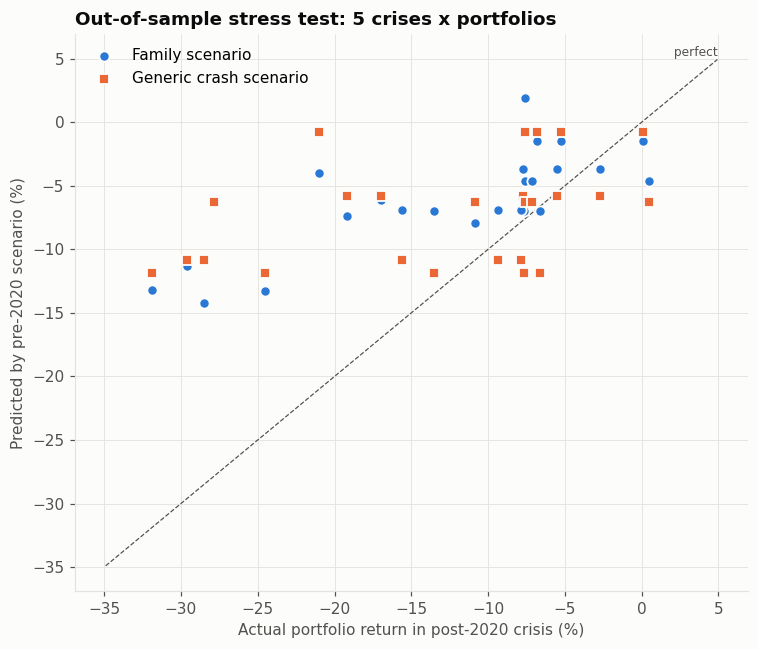

In [1068]:
# Figure 7: predicted vs actual losses, out of sample
if oos[["actual_%", "family_scenario_%"]].dropna().empty:
    print("No out-of-sample results to plot")
else:
    fig, ax = plt.subplots(figsize=(7, 6))
    mk = {"family_scenario_%": (BLUE, "o", "Family scenario"), "generic_scenario_%": (ORANGE, "s", "Generic crash scenario")}
    for col, (c, m, lab) in mk.items():
        ax.scatter(oos["actual_%"], oos[col], color=c, marker=m, s=45, edgecolor=SURFACE, linewidth=1.2,
                   label=lab, zorder=3)
    lo = np.nanmin(oos[["actual_%", "family_scenario_%", "generic_scenario_%"]].values) - 3
    hi = np.nanmax(oos[["actual_%", "family_scenario_%", "generic_scenario_%"]].values) + 3
    ax.plot([lo, hi], [lo, hi], color=INK2, lw=0.8, ls="--")
    ax.text(hi, hi, " perfect", color=INK2, fontsize=8, va="bottom", ha="right")
    ax.set_xlabel("Actual portfolio return in post-2020 crisis (%)")
    ax.set_ylabel("Predicted by pre-2020 scenario (%)")
    ax.set_title("Out-of-sample stress test: 5 crises x portfolios")
    ax.legend(loc="upper left")
    fig.tight_layout(); fig.savefig(FIG / "fig07_out_of_sample.png"); plt.show()

## 18b. Stricter validation: one error per crisis, walk-forward and leave-one-crisis-out
Two weaknesses of the single pre/post-2020 split: the five portfolios inside one crisis are **not independent observations** (they all share the same market move), and five test crises is a very small test. Two stricter designs, both scored with **one error per crisis** (the mean absolute error across portfolios):

- **Walk-forward (expanding window).** Crises are taken in date order; each one is predicted using *only crises that happened before it*. This is the closest to real use. A crisis is scored only if at least one earlier crisis of the same family exists.
- **Leave-one-crisis-out.** Each crisis is predicted from all the *other* 16. This uses more history and shows whether any single crisis drives the result.

Both are run for the level test and the conditional (depth-given) test, family scenario vs generic scenario. The summary reports, for each design, the mean crisis-level error and **in how many crises the family scenario was closer**.

In [1070]:
order = units.assign(ed=pd.to_datetime(units.event_date)).sort_values("ed").code.tolist()
moves_all = fall_f.drop(columns="family")
ratio_all = loss_tbl.drop(columns="S&P 500").div(loss_tbl["S&P 500"].where(loss_tbl["S&P 500"].abs() > 0.5), axis=0)

def predict_crisis(c, pool):
    same = [x for x in pool if fam[x] == fam[c]]
    gen_mv, gen_b = moves_all.loc[pool].median(), ratio_all.loc[pool].median()
    fam_mv = moves_all.loc[same].median() if same else None
    fam_b = ratio_all.loc[same].median() if same else None
    rows = []
    for name, w in PORTS.items():
        act = loss_tbl.loc[c, name]
        r = {"code": c, "family": fam[c], "portfolio": name, "actual": act, "n_same_family_history": len(same),
             "level_family": scenario_loss(w, fam_mv) if same else np.nan,
             "level_generic": scenario_loss(w, gen_mv)}
        if name == "S&P 500":
            r["cond_family"] = r["cond_generic"] = np.nan        # S&P is the conditioning variable itself
        else:
            r["cond_family"] = fam_b[name] * loss_tbl.loc[c, "S&P 500"] if same else np.nan
            r["cond_generic"] = gen_b[name] * loss_tbl.loc[c, "S&P 500"]
        rows.append(r)
    return rows

designs = {
    "walk-forward": [(c, order[:i]) for i, c in enumerate(order) if i >= 3],
    "leave-one-out": [(c, [x for x in order if x != c]) for c in order],
}
crisis_err, summary = [], []
for dname, jobs in designs.items():
    pr = pd.DataFrame([r for c, pool in jobs for r in predict_crisis(c, pool)])
    for test in ("level", "cond"):
        e = pr.assign(fe=(pr[f"{test}_family"] - pr.actual).abs(), ge=(pr[f"{test}_generic"] - pr.actual).abs())
        ce = e.groupby("code").agg(family=("family", "first"), n_hist=("n_same_family_history", "first"),
                                   family_err=("fe", "mean"), generic_err=("ge", "mean"))
        scored = ce.dropna(subset=["family_err", "generic_err"])
        ce["design"], ce["test"] = dname, test
        crisis_err.append(ce.reset_index())
        summary.append({"design": dname, "test": "level" if test == "level" else "conditional (depth given)",
                        "crises_scored": len(scored),
                        "family_mean_err": scored.family_err.mean(), "generic_mean_err": scored.generic_err.mean(),
                        "family_closer_in": f"{int((scored.family_err < scored.generic_err).sum())}/{len(scored)}"})
crisis_err = pd.concat(crisis_err, ignore_index=True)
crisis_err.to_csv(OUT / "stress_validation_by_crisis.csv", index=False)
validation = pd.DataFrame(summary)
validation.to_csv(OUT / "stress_validation_summary.csv", index=False)
display(validation.round(2))
print("Crisis-level errors, walk-forward, level test:")
display(crisis_err[(crisis_err.design == "walk-forward") & (crisis_err.test == "level")]
        .set_index("code").reindex([c for c in order if c in set(crisis_err.code)])
        .dropna(how="all")[["family", "n_hist", "family_err", "generic_err"]].round(1))

,design,test,crises_scored,family_mean_err,generic_mean_err,family_closer_in
0,walk-forward,level,12,7.81,6.54,6/12
1,walk-forward,conditional (depth given),12,2.60,2.61,8/12
2,leave-one-out,level,17,7.86,7.11,9/17
3,leave-one-out,conditional (depth given),17,3.86,3.28,9/17


Crisis-level errors, walk-forward, level test:


,family,n_hist,family_err,generic_err
code,,,,
U4,Sudden event,1.00,2.30,9.80
U5,Sudden event,2.00,3.40,8.30
U6,Growth & credit,0.00,NaN,25.10
U7,Growth & credit,1.00,29.80,8.60
U8,Growth & credit,2.00,10.90,2.00
U9,Growth & credit,3.00,1.90,1.30
U10,Sudden event,3.00,3.10,4.00
U11,Rates & inflation,0.00,NaN,2.20
U12,Rates & inflation,1.00,5.50,5.40


## 19. Method 3: calm-market risk vs crisis risk
**Intuition.** Risk models are usually estimated on normal days. In a crisis, correlations jump ("everything falls together"), volatility explodes, and some hedges flip sign. Two checks:

1. **Betas and correlations to the S&P 500 on calm days vs stress days.** Two regime definitions:
   - *Outcome-selected*: stress days = days inside the fall windows of Part 1. These windows were chosen *because* stocks fell, so this split is conditional on the outcome and can exaggerate differences.
   - *Ex-ante (pre-specified)*: high-fear days = days when the **previous close of the VIX was above 25**, a threshold fixed in the configuration before looking at results. This uses only information available the day before, so it is the fairer test. If both splits tell the same story, the result is not an artefact of selection.
2. **Value-at-Risk vs reality.** For each crisis, a standard 99% parametric VaR is estimated from the portfolio's volatility over the year *before* the event, scaled to the length of the fall ($\text{VaR} = 2.33\,\sigma\sqrt{h}$). A ratio above 1 means the actual loss was larger than the "1-in-100" bound the model allowed.

   *Reading it correctly:* these windows were **chosen because they were crises**, so many breaches are expected; a breach rate here is not the model's unconditional error rate. The informative question is *which kinds* of crisis blow through the bound and by how much. Square-root-of-time scaling also makes the bound very wide for long, grinding falls, so expect fast shocks from calm markets to breach most.

In [1072]:
stress_mask = pd.Series(False, index=prices.index)
for _, w in win.iterrows():
    stress_mask.loc[pd.Timestamp(w.event_base_date):pd.Timestamp(w.event_trough)] = True
stress_mask = stress_mask.loc[CONFIG["analysis_start"]:]

daily = prices[[a for a in ASSET_LIST]].pct_change().loc[CONFIG["analysis_start"]:]
beta_rows = []
for a in [c for c in ASSET_LIST if c != "sp500_tr"]:
    for regime, m in (("calm", ~stress_mask), ("stress", stress_mask)):
        seg = daily.loc[m.values, ["sp500_tr", a]].dropna()
        if len(seg) > 30:
            beta_rows.append({"asset": a, "regime": regime, "days": len(seg),
                              "beta_to_sp500": np.cov(seg[a], seg.sp500_tr)[0, 1] / seg.sp500_tr.var(),
                              "corr_to_sp500": seg[a].corr(seg.sp500_tr),
                              "ann_vol_%": seg[a].std() * np.sqrt(252) * 100})
# ex-ante regime: previous day's VIX close above the threshold
vix_prev = prices["vix"].shift(1).reindex(daily.index) if "vix" in prices else pd.Series(np.nan, index=daily.index)
high_fear = vix_prev > CONFIG["vix_regime_threshold"]
for a in [c for c in ASSET_LIST if c != "sp500_tr"]:
    for regime, m in (("VIX<=25", ~high_fear & vix_prev.notna()), ("VIX>25", high_fear)):
        seg = daily.loc[m.values, ["sp500_tr", a]].dropna()
        if len(seg) > 30:
            beta_rows.append({"asset": a, "regime": regime, "days": len(seg),
                              "beta_to_sp500": np.cov(seg[a], seg.sp500_tr)[0, 1] / seg.sp500_tr.var(),
                              "corr_to_sp500": seg[a].corr(seg.sp500_tr),
                              "ann_vol_%": seg[a].std() * np.sqrt(252) * 100})
betas = pd.DataFrame(beta_rows).pivot(index="asset", columns="regime",
                                      values=["beta_to_sp500", "corr_to_sp500", "ann_vol_%"])
betas = betas.reindex(columns=["calm", "stress", "VIX<=25", "VIX>25"], level=1)
betas.to_csv(OUT / "calm_vs_stress_betas.csv")
print(f"Outcome-selected split: {int(stress_mask.sum())} stress days. "
      f"Ex-ante split: {int(high_fear.sum())} days with previous VIX > {CONFIG['vix_regime_threshold']:.0f}.")
display(betas.round(2))
both = pd.crosstab(stress_mask.reindex(daily.index).fillna(False), high_fear, rownames=["in fall window"], colnames=["prev VIX > 25"])
print("Overlap of the two regime definitions (days):"); display(both)

# stock-bond correlation on stress days, by family
fam_corr = []
for f_name in FAMILY_STYLE:
    m = pd.Series(False, index=daily.index)
    for _, w in win[win.family == f_name].iterrows():
        m.loc[pd.Timestamp(w.event_base_date):pd.Timestamp(w.event_trough)] = True
    seg = daily.loc[m.values, ["sp500_tr", "int_tsy"]].dropna() if "int_tsy" in daily else pd.DataFrame()
    fam_corr.append({"family": f_name, "stress_days": len(seg),
                     "stock_bond_corr": seg.sp500_tr.corr(seg.int_tsy) if len(seg) > 10 else np.nan})
print("Stock-bond correlation on stress days, by shock family:")
display(pd.DataFrame(fam_corr).set_index("family").round(2))

Outcome-selected split: 1590 stress days. Ex-ante split: 1270 days with previous VIX > 25.


/var/folders/9c/0j16jmp51933bz_d44fw4vfm0000gn/T/ipykernel_17488/447010885.py:6: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  daily = prices[[a for a in ASSET_LIST]].pct_change().loc[CONFIG["analysis_start"]:]


beta_to_sp500                       corr_to_sp500                       ann_vol_%                      
regime               calm stress VIX<=25 VIX>25          calm stress VIX<=25 VIX>25      calm stress VIX<=25 VIX>25
asset                                                                                                              
cons_disc            1.06   1.00    1.06   1.01          0.88   0.86    0.83   0.90     17.61  33.95   17.14  38.16
dollar              -0.07  -0.01   -0.04  -0.04         -0.15  -0.04   -0.08  -0.13      7.11   9.29    7.04  10.00
energy               0.96   1.01    0.85   1.07          0.59   0.72    0.51   0.78     23.66  40.91   22.38  47.14
financials           1.17   1.29    1.08   1.34          0.82   0.85    0.80   0.87     20.80  44.17   18.24  52.84
gold                 0.07  -0.05    0.03  -0.01          0.06  -0.07    0.03  -0.01     16.80  21.46   16.48  23.11
health               0.71   0.72    0.73   0.71          0.73   0.81    0.70   0.84     14.10  26.21   13.96  28.96
industrials          1.04   0.94    0.99   0.99          0.88   0.91    0.85   0.93     17.21  30.29   15.58  36.45
int_tsy             -0.05  -0.08   -0.06  -0.07         -0.17  -0.38   -0.19  -0.38      4.47   6.04    4.46   6.44
long_tsy            -0.17  -0.18   -0.17  -0.18         -0.21  -0.37   -0.21  -0.38     11.63  14.28   11.17  16.32
materials            1.06   0.92    0.98   0.99          0.81   0.80    0.73   0.86     19.07  33.93   18.00  39.27
oil                  0.41   0.46    0.34   0.50          0.15   0.26    0.14   0.24     39.20  53.46   33.53  69.74
staples              0.52   0.53    0.51   0.54          0.64   0.70    0.57   0.76     11.80  22.23   11.90  24.05
tech                 1.22   1.15    1.26   1.13          0.87   0.88    0.85   0.90     20.37  38.37   19.94  42.96
utilities            0.55   0.65    0.49   0.68          0.52   0.68    0.45   0.73     15.49  27.95   14.64  32.17

Overlap of the two regime definitions (days):


prev VIX > 25,False,True
in fall window,,
False,4588,559
True,879,711


Stock-bond correlation on stress days, by shock family:


,stress_days,stock_bond_corr
family,,
Growth & credit,723,-0.52
Rates & inflation,254,0.05
Valuation unwind,495,-0.32
Sudden event,118,-0.38


In [1073]:
var_rows = []
for name, w in PORTS.items():
    for _, u in units.iterrows():
        i_b = loc(pd.Timestamp(u.event_base_date))
        hist = portfolio_returns_before(w, u.event_base_date, CONFIG["var_lookback_days"])  # buy-and-hold, prior year
        if hist is None:
            continue
        h = max(loc(pd.Timestamp(u.event_trough)) - i_b, 1)
        actual = loss_tbl.loc[u.code, name]
        if len(hist) < 100 or pd.isna(actual):
            continue
        var = -CONFIG["var_z"] * hist.std() * np.sqrt(h) * 100
        var_rows.append({"code": u.code, "family": u.family, "portfolio": name, "horizon_days": h,
                         "VaR99_%": var, "actual_%": actual, "loss_to_VaR": actual / var,
                         "breach": actual < var})
var_tbl = pd.DataFrame(var_rows)
var_tbl.to_csv(OUT / "stress_var_check.csv", index=False)
print("Share of crisis windows where the loss exceeded the prior-year 99% VaR (windows are selected crises, so this is not an unconditional error rate):")
display(var_tbl.groupby("portfolio").breach.mean().mul(100).round(0).rename("% breached").to_frame())
print("Median actual loss / VaR, by family (above 1 = model too optimistic):")
display(var_tbl.pivot_table(index="family", columns="portfolio", values="loss_to_VaR", aggfunc="median").round(2))

Share of crisis windows where the loss exceeded the prior-year 99% VaR (windows are selected crises, so this is not an unconditional error rate):


,% breached
portfolio,
60/40,53.00
Defensive,35.00
Diversified,38.00
S&P 500,59.00
Tech tilt,53.00


Median actual loss / VaR, by family (above 1 = model too optimistic):


portfolio,60/40,Defensive,Diversified,S&P 500,Tech tilt
family,,,,,
Growth & credit,0.94,0.44,-0.05,1.09,0.91
Rates & inflation,1.23,0.84,1.44,1.37,1.27
Sudden event,1.32,0.84,0.98,1.49,1.28
Valuation unwind,0.40,0.34,0.20,0.63,0.71


## 20. Method 4: reverse stress test
Instead of asking "how much would we lose in scenario X?", ask "**how bad would a crash of each type have to be to cost us 20%?**" The family's typical scenario is scaled up or down (linearly) until the portfolio loses 20%, and the implied S&P 500 fall is reported. A *small* implied fall means the portfolio is fragile to that type of shock. "Beyond any crash since 2000" means the required fall is deeper than the worst full-cycle decline in the sample (the 2007-09 crisis), so the portfolio is robust to that shock type; "not reachable" means it would take more than a 100% fall, or the portfolio gains in that scenario. **These are sensitivity calculations, not forecasts.** Linear scaling assumes every asset moves in the same proportion as the crash grows; in real crises, stock-bond relationships and hedges can change as shocks get larger.

In [1075]:
target = CONFIG["reverse_target_loss_pct"]
worst_ever = units.cycle_depth_pct.min()      # deepest full-cycle fall since 2000
rev = []
for _, s in scenarios[scenarios.scenario == "Typical"].iterrows():
    row = {"family": s.family, "typical_S&P_move_%": s["S&P 500 move"]}
    for name in PORTS:
        L = s[name]
        if pd.isna(L) or L >= 0:
            row[name] = "not reachable"
        else:
            k = target / L
            implied = k * s["S&P 500 move"]
            if implied <= -100:
                row[name] = "not reachable"
            elif implied < worst_ever:
                row[name] = f"{implied:.0f}% S&P (beyond any crash since 2000)"
            else:
                row[name] = f"{implied:.0f}% S&P (x{k:.1f})"
    rev.append(row)
reverse = pd.DataFrame(rev).set_index("family")
reverse.to_csv(OUT / "stress_reverse.csv")
print(f"S&P 500 fall needed for each portfolio to lose {abs(target):.0f}%, by shock family:")
display(reverse)

S&P 500 fall needed for each portfolio to lose 20%, by shock family:


,typical_S&P_move_%,S&P 500,60/40,Tech tilt,Defensive,Diversified
family,,,,,,
Growth & credit,-14.26,-20% S&P (x1.4),-44% S&P (x3.1),-23% S&P (x1.6),-37% S&P (x2.6),not reachable
Rates & inflation,-18.06,-20% S&P (x1.1),-33% S&P (x1.8),-19% S&P (x1.0),-44% S&P (x2.4),-45% S&P (x2.5)
Sudden event,-7.69,-20% S&P (x2.6),-37% S&P (x4.9),-20% S&P (x2.5),-30% S&P (x3.9),-68% S&P (beyond any crash since 2000)
Valuation unwind,-26.86,-20% S&P (x0.7),-55% S&P (x2.1),-13% S&P (x0.5),-62% S&P (beyond any crash since 2000),not reachable


## 20b. Why did each portfolio win or lose?
The replay (Section 17) says *how much* each portfolio lost; this section asks *why*. Three tools:

1. **Loss attribution.** In a buy-and-hold portfolio, the loss is exactly the sum of each holding's weight times its return. Splitting it shows which holding did the damage and which cushioned it. For 60/40, how much of the 2022 loss came from the bonds?
2. **Hedge effectiveness.** For each hedge asset (intermediate and long Treasuries, gold): how much did it gain for every 1% the S&P 500 fell? Positive = it hedged; negative = it fell *with* stocks.
3. **Recovery paths.** Falling less is only half the story. Each portfolio's value relative to its starting point is tracked 1, 3, 6 and 12 months after the S&P bottom: does a portfolio that fell less also recover sooner?

**Intuition to test.** A hedge is only as good as the *reason* stocks are falling. Bonds should offset a large share of the stock loss in growth crises and a negative share in rate shocks. Gold should help in fear and growth crises but not when real interest rates are rising.

In [1077]:
EQUITY_ASSETS = ["sp500_tr"] + SECTORS
HEDGE_ASSETS = [h for h in ["int_tsy", "long_tsy", "gold"] if h in fall]

# 1. loss attribution: contribution of each holding = weight x return over the fall window
contrib = pd.DataFrame([{"code": c, "family": fam[c], "portfolio": name, "asset": a, "weight": wt,
                         "asset_return_%": fall.loc[c, a] if a in fall else np.nan,
                         "contribution_pts": wt * fall.loc[c, a] if a in fall else np.nan}
                        for c in units.code for name, w in PORTS.items() for a, wt in w.items()])
contrib.to_csv(OUT / "stress_loss_attribution.csv", index=False)
chk = contrib.groupby(["code", "portfolio"]).contribution_pts.sum(min_count=1).unstack()[list(PORTS)].reindex(loss_tbl.index)
print(f"Check: attribution adds up to the replay loss (max gap {np.nanmax(np.abs(chk.values - loss_tbl.values)):.2f} pts)")

for name in [p for p in ["60/40", "Diversified"] if p in PORTS]:
    t = contrib[contrib.portfolio == name].pivot(index="code", columns="asset", values="contribution_pts").reindex(units.code)
    t["total"] = t.sum(axis=1, min_count=t.shape[1])
    print(f"\n{name}: contribution of each holding to the loss (pts)")
    display(t.join(fam).round(1))

# portfolio-level hedge offset: share of the equity loss cancelled by the hedge holdings
off_rows = []
for c in units.code:
    for name, w in PORTS.items():
        eq = sum(wt * fall.loc[c, a] for a, wt in w.items() if a in EQUITY_ASSETS and a in fall)
        hg = [wt * fall.loc[c, a] for a, wt in w.items() if a in HEDGE_ASSETS]
        if hg and eq < 0 and not any(pd.isna(hg)):
            off_rows.append({"code": c, "family": fam[c], "portfolio": name,
                             "equity_pts": eq, "hedge_pts": sum(hg), "offset_%": -100 * sum(hg) / eq})
offset = pd.DataFrame(off_rows)
offset.to_csv(OUT / "stress_hedge_offset.csv", index=False)
print("\nShare of the equity loss offset by the hedge holdings (%; 100 = fully offset, negative = hedges added to the loss)")
display(offset.pivot(index="code", columns="portfolio", values="offset_%").reindex(units.code).join(fam).round(0))
display(offset.pivot_table(index="family", columns="portfolio", values="offset_%", aggfunc="median").round(0))

Check: attribution adds up to the replay loss (max gap 0.00 pts)

60/40: contribution of each holding to the loss (pts)


,int_tsy,sp500_tr,total,family
code,,,,
U1,7.40,-13.80,-6.50,Valuation unwind
U2,0.50,-6.90,-6.40,Sudden event
U3,5.50,-18.40,-12.90,Valuation unwind
U4,0.80,-5.20,-4.40,Sudden event
U5,0.40,-3.10,-2.70,Sudden event
U6,7.50,-31.40,-23.90,Growth & credit
U7,2.00,-3.60,-1.60,Growth & credit
U8,1.50,-8.60,-7.10,Growth & credit
U9,1.50,-7.30,-5.70,Growth & credit



Diversified: contribution of each holding to the loss (pts)


,gold,int_tsy,long_tsy,sp500_tr,total,family
code,,,,,,
U1,NaN,2.80,6.80,-9.20,NaN,Valuation unwind
U2,1.10,0.20,-0.20,-4.60,-3.60,Sudden event
U3,2.20,2.10,4.90,-12.30,-3.10,Valuation unwind
U4,0.10,0.30,1.00,-3.50,-2.10,Sudden event
U5,-1.10,0.20,0.40,-2.10,-2.60,Sudden event
U6,5.70,2.80,6.50,-20.90,-5.90,Growth & credit
U7,1.30,0.70,3.40,-2.40,3.00,Growth & credit
U8,0.30,0.60,6.50,-5.70,1.70,Growth & credit
U9,2.00,0.60,2.90,-4.90,0.50,Growth & credit



Share of the equity loss offset by the hedge holdings (%; 100 = fully offset, negative = hedges added to the loss)


,60/40,Diversified,family
code,,,
U1,53.00,NaN,Valuation unwind
U2,7.00,23.00,Sudden event
U3,30.00,75.00,Valuation unwind
U4,15.00,39.00,Sudden event
U5,13.00,-27.00,Sudden event
U6,24.00,72.00,Growth & credit
U7,55.00,224.00,Growth & credit
U8,17.00,129.00,Growth & credit
U9,21.00,111.00,Growth & credit


portfolio,60/40,Diversified
family,,
Growth & credit,21.00,111.00
Rates & inflation,0.00,-24.00
Sudden event,13.00,23.00
Valuation unwind,42.00,75.00


In [1078]:
# 2. hedge effectiveness of each asset: gain per 1% fall of the S&P 500
he = pd.DataFrame({h: -fall[h] / fall["sp500_tr"].where(fall["sp500_tr"] < -1) for h in HEDGE_ASSETS}).reindex(units.code)
he.to_csv(OUT / "hedge_effectiveness.csv")
print("Gain (%) of each hedge asset per 1% fall in the S&P 500 (negative = fell with stocks)")
display(he.join(fam).round(2))
he_f = he.join(fam).groupby("family").agg(["median", "min", "max"])
display(he_f.round(2))

Gain (%) of each hedge asset per 1% fall in the S&P 500 (negative = fell with stocks)


,int_tsy,long_tsy,gold,family
code,,,,
U1,0.80,0.98,NaN,Valuation unwind
U2,0.11,-0.07,0.65,Sudden event
U3,0.45,0.53,0.48,Valuation unwind
U4,0.22,0.37,0.10,Sudden event
U5,0.20,0.25,-1.41,Sudden event
U6,0.36,0.42,0.73,Growth & credit
U7,0.83,1.86,1.43,Growth & credit
U8,0.26,1.51,0.16,Growth & credit
U9,0.32,0.78,1.07,Growth & credit


int_tsy            long_tsy              gold           
                   median   min  max   median   min  max median   min  max
family                                                                    
Growth & credit      0.32  0.17 0.83     0.78  0.42 1.86   0.73 -0.01 1.43
Rates & inflation    0.00 -0.45 0.15    -0.20 -1.14 0.38  -0.24 -0.31 0.37
Sudden event         0.20 -0.29 0.47     0.25 -0.57 1.02   0.19 -1.79 0.91
Valuation unwind     0.62  0.45 0.80     0.76  0.53 0.98   0.48  0.48 0.48

In [1079]:
# 3. recovery paths after the S&P 500 trough
HORIZONS = {"trough": 0, "+1m": 21, "+3m": 63, "+6m": 126, "+12m": 252}
rp_rows = []
for _, u in units.iterrows():
    i_tr = loc(pd.Timestamp(u.event_trough)) - loc(pd.Timestamp(u.event_base_date))
    for name, w in PORTS.items():
        path = portfolio_path(w, u.event_base_date, i_tr + 252)
        if path is None:
            continue
        for lab, k in HORIZONS.items():
            if i_tr + k < len(path):
                rp_rows.append({"code": u.code, "family": u.family, "portfolio": name, "horizon": lab,
                                "value_vs_start_%": 100 * (path.iloc[i_tr + k] - 1)})
rpaths = pd.DataFrame(rp_rows)
rpaths.to_csv(OUT / "stress_recovery_paths.csv", index=False)
tbl = rpaths.pivot_table(index=["family", "portfolio"], columns="horizon", values="value_vs_start_%", aggfunc="median")
print("Portfolio value vs starting value (%), median across the family's crises, at and after the S&P trough")
display(tbl[list(HORIZONS)].round(1))
gain = rpaths[rpaths.horizon.isin(["trough", "+12m"])].pivot_table(index=["code", "portfolio"], columns="horizon",
                                                                  values="value_vs_start_%")
gain["rebound_pts"] = gain["+12m"] - gain["trough"]
print("Rebound in the 12 months after the trough (pts), median by family:")
display(gain.reset_index().merge(units[["code", "family"]], on="code")
        .pivot_table(index="family", columns="portfolio", values="rebound_pts", aggfunc="median").round(1))

Portfolio value vs starting value (%), median across the family's crises, at and after the S&P trough


horizon                        trough    +1m    +3m    +6m   +12m
family            portfolio                                      
Growth & credit   60/40         -7.10  -1.60   1.30   5.60  11.90
                  Defensive     -5.80   0.70   4.60   8.10   8.40
                  Diversified    0.50   2.70   5.50   9.70  11.80
                  S&P 500      -14.30  -4.80  -0.30   6.10  15.20
                  Tech tilt    -12.20  -3.20   0.50   9.20  18.50
Rates & inflation 60/40         -9.70  -3.00  -2.00   1.40   0.00
                  Defensive     -9.10  -2.90   0.70   1.60   4.90
                  Diversified   -4.20  -1.20  -1.90  -0.50   0.30
                  S&P 500      -18.10  -7.00  -3.00   2.10  -2.20
                  Tech tilt    -19.40  -8.20  -0.50   5.10  -0.80
Sudden event      60/40         -4.40   0.80   4.00   5.20  10.80
                  Defensive     -7.20  -1.80   0.60   3.70   8.40
                  Diversified   -2.60   0.80   3.20   2.40  11.20
                  S&P 500       -7.70  -0.50   6.70   9.80  16.10
                  Tech tilt     -8.30  -0.90   8.00  10.30  19.30
Valuation unwind  60/40         -9.70  -3.10  -3.50  -6.20  -0.30
                  Defensive     -8.70  -1.90  -1.60  -7.20  -0.50
                  Diversified   -3.10   0.70   3.00   1.30  10.00
                  S&P 500      -26.90 -15.50 -15.80 -23.70 -13.90
                  Tech tilt    -41.40 -28.40 -28.40 -37.50 -27.90

Rebound in the 12 months after the trough (pts), median by family:


portfolio,60/40,Defensive,Diversified,S&P 500,Tech tilt
family,,,,,
Growth & credit,20.30,26.20,16.40,31.40,30.70
Rates & inflation,10.40,11.70,7.20,17.30,24.20
Sudden event,13.50,9.00,12.50,22.10,26.80
Valuation unwind,9.40,8.20,13.00,13.00,13.50


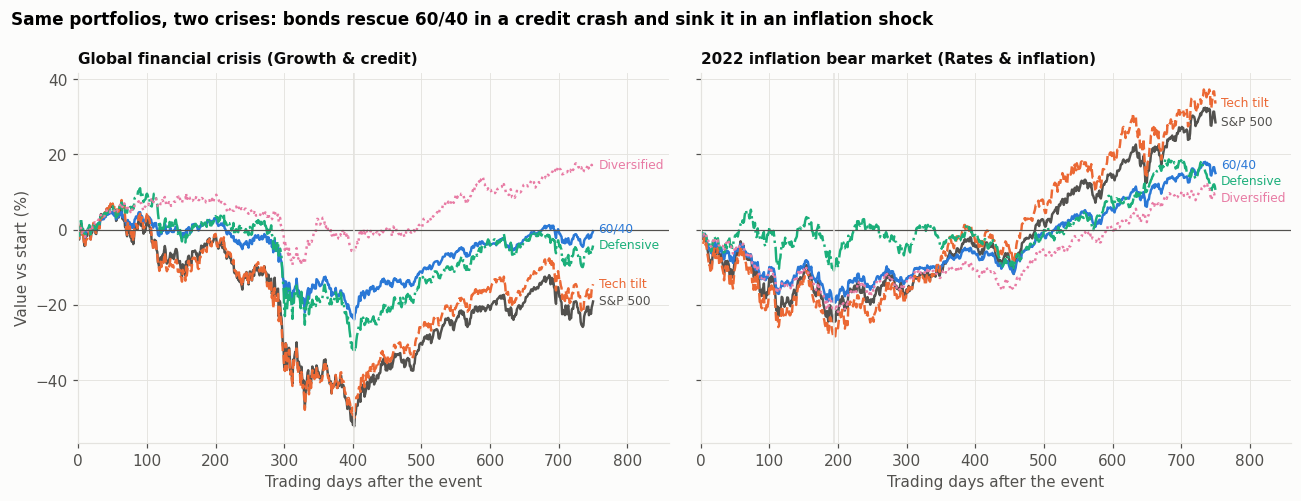

In [1080]:
# Figure 8: the same portfolios in two different crises (2008 vs 2022)
PORT_STYLE = dict(zip(PORTS, [(INK2, "-"), (BLUE, "-"), (ORANGE, "--"), (AQUA, "-."), ("#e87ba4", ":")]))
pair = [c for c in ["U6", "U14"] if c in set(units.code)]
fig, axes = plt.subplots(1, len(pair), figsize=(12, 4.6), sharey=True)
axes = np.atleast_1d(axes)
for ax, c in zip(axes, pair):
    u = units.set_index("code").loc[c]
    ends = []
    for name, w in PORTS.items():
        path = portfolio_path(w, u.event_base_date, 750)
        if path is None:
            continue
        col, ls = PORT_STYLE[name]
        x = np.arange(len(path))
        ax.plot(x, 100 * (path.values - 1), color=col, ls=ls, lw=1.6)
        ends.append([100 * (path.values[-1] - 1), name, col, x[-1]])
    ends.sort(key=lambda e: e[0])                      # spread end labels at least 4.5 pts apart
    for i in range(1, len(ends)):
        ends[i][0] = max(ends[i][0], ends[i - 1][0] + 4.5)
    for yv, name, col, xe in ends:
        ax.text(xe + 8, yv, name, fontsize=8, color=col, va="center")
    ax.axhline(0, color=INK2, lw=0.8)
    ax.axvline(loc(pd.Timestamp(u.event_trough)) - loc(pd.Timestamp(u.event_base_date)), color=GRID, lw=1)
    ax.set_title(f"{u.unit.split(' ', 1)[1]} ({u.family})", fontsize=10)
    ax.set_xlabel("Trading days after the event")
    ax.set_xlim(0, 860)
axes[0].set_ylabel("Value vs start (%)")
fig.suptitle("Same portfolios, two crises: bonds rescue 60/40 in a credit crash and sink it in an inflation shock",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "fig08_two_crises_paths.png"); plt.show()

## 20c. Forward-looking what-if scenarios
The validation in Section 18b showed that **history alone does not anticipate new regimes**: 2022 was the first inflation shock in the sample, and nothing before it warned that bonds would fall with stocks. Risk managers handle this with *hypothetical* scenarios: plausible shocks that are worse than, or different from, anything in the data.

**How the scenario engine works.** A scenario is defined by four market drivers, and each portfolio holding is mapped to them using relationships estimated from the data:

| Holding | How its move is set |
|---|---|
| S&P 500 | The scenario's equity fall |
| Sectors | Sector sensitivity to the S&P 500 and to oil, estimated **on high-fear days only** (previous VIX > 25), because calm-day relationships understate crisis co-movement (Section 19) |
| Treasuries | Bond sensitivity to changes in the 10-year yield (empirical duration), so bonds fall when yields rise |
| Gold, oil | Set directly by the scenario |

**Five scenarios**, each anchored on a real episode but pushed further:

| Scenario | S&P 500 | 10-yr yield | Oil | Gold | Anchor | The question it asks |
|---|---|---|---|---|---|---|
| Deflationary bust | −35% | −150 bp | −40% | +15% | 2008, COVID | The crash 60/40 was designed for |
| Stagflation | −25% | +150 bp | +40% | 0% | 2022 with an oil shock | What if bonds fail *and* oil soars? |
| Oil supply shock | −12% | +50 bp | +80% | −10% | Iran war 2026, larger | A war-driven inflation scare |
| Sell America | −20% | +75 bp | −10% | +15% | April 2025, larger | Investors sell U.S. stocks *and* bonds |
| Dash for cash | −30% | +25 bp | −40% | −10% | March 2020 | Everything is sold for cash at once |

Each is run at **mild (×0.5), moderate (×1) and severe (×1.5)** strength. The engine is checked two ways on the real crises, feeding in each crisis's actual S&P, yield, oil and gold moves:
- **In-sample reconstruction**: sensitivities estimated on the full sample. This is a consistency check that the engine can rebuild historical outcomes, not evidence of predictive power.
- **Walk-forward test**: for each crisis, sensitivities are re-estimated using **only data before its event date**, then used to predict that crisis. This is the out-of-sample test of the engine's translation from market moves to portfolio losses.

Neither test checks the hard part of a real forecast, which is guessing the market moves themselves.

*Caveat:* these are sensitivity calculations, not forecasts. Daily sensitivities are scaled linearly to large shocks, and the sensitivities are estimated on the full sample.

In [1082]:
def ols(y, X):
    m = y.notna() & X.notna().all(axis=1)
    A = np.column_stack([np.ones(int(m.sum())), X[m].values])
    return np.linalg.lstsq(A, y[m].values, rcond=None)[0][1:], int(m.sum())

dy = prices["ust10y"].diff().reindex(daily.index) if "ust10y" in prices else pd.Series(np.nan, index=daily.index)
fear = high_fear.reindex(daily.index).fillna(False)

def estimate_engine(before=None):
    # sensitivities from data strictly before `before` (None = full sample)
    keep = pd.Series(True, index=daily.index) if before is None else pd.Series(daily.index < pd.Timestamp(before), index=daily.index)
    f_ = fear & keep
    rows_ = []
    for a in [s_ for s_ in SECTORS if s_ in daily]:
        (b_sp, b_oil), n = ols(daily[a][f_], daily[["sp500_tr", "oil"]][f_])
        rows_.append({"asset": a, "beta_sp500": b_sp, "beta_oil": b_oil, "duration": np.nan, "days": n, "estimated_on": "VIX>25 days"})
    for a in [b for b in ["int_tsy", "long_tsy"] if b in daily]:
        (dur,), n = ols(daily[a][keep], dy[keep].to_frame())
        (dur_f,), _ = ols(daily[a][f_], dy[f_].to_frame())
        rows_.append({"asset": a, "beta_sp500": np.nan, "beta_oil": np.nan, "duration": -100 * dur,
                      "duration_fear_days": -100 * dur_f, "days": n, "estimated_on": "all days (yield changes)"})
    return pd.DataFrame(rows_).set_index("asset"), int(f_.sum())

engine, _ = estimate_engine()
engine.to_csv(OUT / "what_if_sensitivities.csv")
print("Scenario engine sensitivities (duration = % price change for a 1-point fall in the 10-year yield):")
display(engine.round(2))

def asset_move(a, drv, eng=None):
    eng = engine if eng is None else eng
    if a == "sp500_tr":
        return drv["sp"]
    if a in ("gold", "oil"):
        return drv[a]
    if a in eng.index and pd.notna(eng.loc[a, "duration"]):
        return -eng.loc[a, "duration"] * drv["dy_bp"] / 100
    if a in eng.index:
        return eng.loc[a, "beta_sp500"] * drv["sp"] + eng.loc[a, "beta_oil"] * drv["oil"]
    return np.nan

def engine_loss(w, drv, eng=None):
    mv = [asset_move(a, drv, eng) for a in w]
    return np.nan if any(pd.isna(mv)) else float(sum(wt * m for wt, m in zip(w.values(), mv)))

# back-test: feed in each real crisis's actual drivers
bt_rows = []
for c in units.code:
    drv = {"sp": fall.loc[c, "sp500_tr"], "dy_bp": rates.loc[c, "ust10y_bp"],
           "oil": fall.loc[c, "oil"] if "oil" in fall else np.nan, "gold": fall.loc[c, "gold"] if "gold" in fall else np.nan}
    if any(pd.isna(list(drv.values()))):
        continue
    eng_wf, n_fear = estimate_engine(before=units.set_index("code").loc[c, "event_date"])
    wf_ok = n_fear >= 60                                  # need enough earlier high-fear days
    for name, w in PORTS.items():
        bt_rows.append({"code": c, "family": fam[c], "portfolio": name,
                        "actual_%": loss_tbl.loc[c, name], "engine_%": engine_loss(w, drv),
                        "engine_walkforward_%": engine_loss(w, drv, eng_wf) if wf_ok else np.nan,
                        "fear_days_before": n_fear})
bt = pd.DataFrame(bt_rows)
bt["abs_err"] = (bt["engine_%"] - bt["actual_%"]).abs()
bt["abs_err_wf"] = (bt["engine_walkforward_%"] - bt["actual_%"]).abs()
bt.to_csv(OUT / "what_if_engine_backtest.csv", index=False)
print("IN-SAMPLE RECONSTRUCTION (consistency check): mean absolute error (pts) and correlation with actual losses")
bt_sum = bt.groupby("portfolio").agg(crises=("code", "count"), mean_abs_err=("abs_err", "mean"))
bt_sum["corr_with_actual"] = [bt[bt.portfolio == p_]["actual_%"].corr(bt[bt.portfolio == p_]["engine_%"]) for p_ in bt_sum.index]
display(bt_sum.round(2))
print(f"In-sample: mean abs error {bt.abs_err.mean():.1f} pts, correlation {bt['actual_%'].corr(bt['engine_%']):.2f}")
wf = bt.dropna(subset=["engine_walkforward_%"])
same = bt.loc[wf.index]
print(f"WALK-FORWARD (sensitivities from data before each crisis): {wf.code.nunique()} crises scored, "
      f"mean abs error {wf.abs_err_wf.mean():.1f} pts vs {same.abs_err.mean():.1f} pts in-sample on the same crises, "
      f"correlation {wf['actual_%'].corr(wf['engine_walkforward_%']):.2f}")
display(wf.groupby("code")[["abs_err", "abs_err_wf"]].mean().round(1)
        .rename(columns={"abs_err": "in_sample_err", "abs_err_wf": "walk_forward_err"}))

Scenario engine sensitivities (duration = % price change for a 1-point fall in the 10-year yield):


,beta_sp500,beta_oil,duration,days,estimated_on,duration_fear_days
asset,,,,,,
tech,1.13,-0.02,NaN,1232,VIX>25 days,NaN
financials,1.36,-0.03,NaN,1232,VIX>25 days,NaN
energy,1.00,0.18,NaN,1232,VIX>25 days,NaN
health,0.72,-0.01,NaN,1232,VIX>25 days,NaN
cons_disc,1.02,-0.02,NaN,1232,VIX>25 days,NaN
staples,0.54,-0.01,NaN,1232,VIX>25 days,NaN
industrials,0.99,-0.00,NaN,1232,VIX>25 days,NaN
materials,0.99,0.02,NaN,1232,VIX>25 days,NaN
utilities,0.70,-0.01,NaN,1232,VIX>25 days,NaN


IN-SAMPLE RECONSTRUCTION (consistency check): mean absolute error (pts) and correlation with actual losses


,crises,mean_abs_err,corr_with_actual
portfolio,,,
60/40,16,0.62,0.99
Defensive,16,2.66,0.93
Diversified,16,0.69,0.99
S&P 500,16,0.00,1.00
Tech tilt,16,2.04,0.98


In-sample: mean abs error 1.2 pts, correlation 0.98
WALK-FORWARD (sensitivities from data before each crisis): 16 crises scored, mean abs error 1.5 pts vs 1.2 pts in-sample on the same crises, correlation 0.97


,in_sample_err,walk_forward_err
code,,
U10,0.50,0.40
U11,0.30,0.40
U12,0.70,0.70
U13,2.60,2.80
U14,1.60,1.80
U15,1.60,1.60
U16,0.60,0.70
U17,0.50,0.50
U2,0.50,1.70


In [1083]:
SCN, SEV = CONFIG["what_if_scenarios"], CONFIG["what_if_severity"]
wi_rows = []
for sname, base in SCN.items():
    for sev, k in SEV.items():
        drv = {key: base[key] * k for key in ("sp", "dy_bp", "oil", "gold")}
        row = {"scenario": sname, "severity": sev, "S&P_%": drv["sp"], "10y_bp": drv["dy_bp"],
               "oil_%": drv["oil"], "gold_%": drv["gold"]}
        row.update({name: engine_loss(w, drv) for name, w in PORTS.items()})
        wi_rows.append(row)
what_if = pd.DataFrame(wi_rows)
what_if.to_csv(OUT / "what_if_scenarios.csv", index=False)
print("Portfolio return (%) in each what-if scenario")
display(what_if.round(1))

mod = what_if[what_if.severity == "Moderate"].set_index("scenario")[list(PORTS)]
summary_wi = pd.DataFrame({
    "worst_scenario": mod.idxmin(),
    "worst_loss_%": mod.min(),
    "best_scenario": mod.idxmax(),
    "range_pts": mod.max() - mod.min(),
    "moderate_scenarios_losing_>10%": (mod < -10).sum(),
})
print("Moderate severity: each portfolio's worst case and how uneven its exposure is")
display(summary_wi.round(1))

# break point: severity multiple at which each portfolio loses 20%
brk = pd.DataFrame({name: [(CONFIG["reverse_target_loss_pct"] / v) if v < 0 else np.nan for v in mod[name]]
                    for name in PORTS}, index=mod.index)
brk.to_csv(OUT / "what_if_break_points.csv")
print(f"Severity multiple needed for a {abs(CONFIG['reverse_target_loss_pct']):.0f}% loss (x1 = moderate; blank = portfolio gains)")
display(brk.round(2))

Portfolio return (%) in each what-if scenario


,scenario,severity,S&P_%,10y_bp,oil_%,gold_%,S&P 500,60/40,Tech tilt,Defensive,Diversified
0,Deflationary bust,Mild,-17.50,-75.00,-20.00,7.50,-17.50,-9.00,-18.50,-11.20,-2.60
1,Deflationary bust,Moderate,-35.00,-150.00,-40.00,15.00,-35.00,-18.00,-36.90,-22.40,-5.20
2,Deflationary bust,Severe,-52.50,-225.00,-60.00,22.50,-52.50,-27.10,-55.40,-33.60,-7.90
3,Stagflation,Mild,-12.50,75.00,20.00,0.00,-12.50,-9.00,-13.50,-8.40,-8.30
4,Stagflation,Moderate,-25.00,150.00,40.00,0.00,-25.00,-18.00,-26.90,-16.70,-16.50
5,Stagflation,Severe,-37.50,225.00,60.00,0.00,-37.50,-26.90,-40.40,-25.10,-24.80
6,Oil supply shock,Mild,-6.00,25.00,40.00,-5.00,-6.00,-4.10,-6.70,-4.40,-4.20
7,Oil supply shock,Moderate,-12.00,50.00,80.00,-10.00,-12.00,-8.20,-13.40,-8.70,-8.50
8,Oil supply shock,Severe,-18.00,75.00,120.00,-15.00,-18.00,-12.30,-20.10,-13.10,-12.70
9,Sell America,Mild,-10.00,37.50,-5.00,7.50,-10.00,-6.70,-10.60,-6.50,-4.50


Moderate severity: each portfolio's worst case and how uneven its exposure is


,worst_scenario,worst_loss_%,best_scenario,range_pts,moderate_scenarios_losing_>10%
S&P 500,Deflationary bust,-35.00,Oil supply shock,23.00,5
60/40,Dash for cash,-18.50,Oil supply shock,10.30,4
Tech tilt,Deflationary bust,-36.90,Oil supply shock,23.50,5
Defensive,Deflationary bust,-22.40,Oil supply shock,13.70,4
Diversified,Stagflation,-16.50,Deflationary bust,11.30,2


Severity multiple needed for a 20% loss (x1 = moderate; blank = portfolio gains)


,S&P 500,60/40,Tech tilt,Defensive,Diversified
scenario,,,,,
Deflationary bust,0.57,1.11,0.54,0.89,3.82
Stagflation,0.80,1.11,0.74,1.19,1.21
Oil supply shock,1.67,2.44,1.49,2.30,2.36
Sell America,1.00,1.48,0.94,1.55,2.22
Dash for cash,0.67,1.08,0.63,1.05,1.37


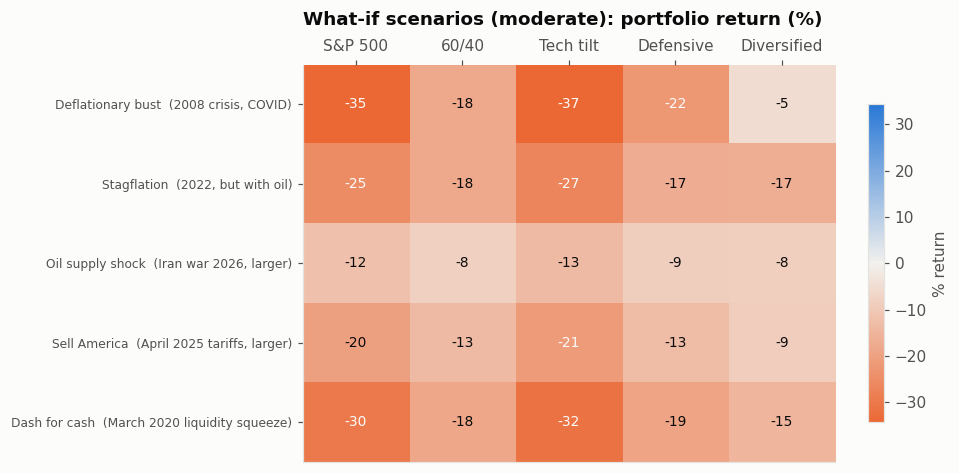

In [1084]:
# Figure 9: what-if heat map (moderate severity)
mat = mod
lim = np.nanpercentile(np.abs(mat.values), 95)
fig, ax = plt.subplots(figsize=(9, 4.4))
im = ax.imshow(mat.values, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(mat.shape[1]), mat.columns)
ax.set_yticks(range(len(mat)), [f"{s_}  ({SCN[s_]['anchor']})" for s_ in mat.index], fontsize=8)
ax.grid(False)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        ax.text(j, i, "" if np.isnan(v) else f"{v:.0f}", ha="center", va="center", fontsize=9,
                color=INK if abs(v) < 0.6 * lim else SURFACE)
ax.xaxis.tick_top()
ax.set_title("What-if scenarios (moderate): portfolio return (%)", pad=26)
fig.colorbar(im, ax=ax, shrink=0.8, label="% return")
fig.tight_layout(); fig.savefig(FIG / "fig09_what_if.png"); plt.show()

---
## 21. Are the conclusions robust? Reclassification, consolidation and leave-one-out
With 2–7 crises per family, a single crisis or a single labelling choice could drive a family median. This section re-computes the headline statistics under alternative choices:

| Variant | Change | Why |
|---|---|---|
| Baseline | Families as assigned in Section 8 | |
| Iran war → Rates & inflation | U17 moved | Oil shock behaved like an inflation shock (bonds and gold fell) |
| Tariffs 2025 → Rates & inflation | U16 moved | Tariffs raise prices; long bonds and the dollar fell |
| Volmageddon → Sudden event | U11 moved | A positioning/volatility-product event as much as a rates scare |
| Overlapping bear consolidated | U2 9/11, U3 2002 bear, U4 Iraq removed | All three sit inside the 2000-02 bear market; keeps one dot-com unit |
| All three reclassifications | U11, U16, U17 moved together | Worst case for the baseline labels |

Then **leave-one-out**: each crisis is dropped in turn, and the range of every family statistic is reported. A conclusion is robust if it holds in every variant and across the leave-one-out range.

In [1086]:
def family_stats(fmap, codes):
    rows = []
    for f_name in FAMILY_STYLE:
        cs = [c for c in codes if fmap[c] == f_name]
        if not cs:
            continue
        tsy = fall.loc[cs, "int_tsy"].dropna() if "int_tsy" in fall else pd.Series(dtype=float)
        rows.append({"family": f_name, "n": len(cs),
                     "median_event_fall_%": units.set_index("code").loc[cs, "event_depth_pct"].median(),
                     "median_days_to_recover": units.set_index("code").loc[cs, "event_days_to_recover"].fillna(np.inf).median(),
                     "treasury_gain_share": (tsy > 0).mean() if len(tsy) else np.nan,
                     "median_treasury_%": tsy.median() if len(tsy) else np.nan,
                     "median_def_minus_cyc_%": rot.loc[cs, "defensive_minus_cyclical_fall"].median(),
                     "median_6040_minus_sp_%": (loss_tbl.loc[cs, "60/40"] - loss_tbl.loc[cs, "S&P 500"]).median()
                                               if "60/40" in loss_tbl else np.nan})
    return pd.DataFrame(rows)

base_map = units.set_index("code").family.to_dict()
def remap(**moves):
    m = dict(base_map); m.update(moves); return m
all_codes = list(units.code)
variants = {
    "Baseline": (base_map, all_codes),
    "Iran war -> Rates & inflation": (remap(U17="Rates & inflation"), all_codes),
    "Tariffs 2025 -> Rates & inflation": (remap(U16="Rates & inflation"), all_codes),
    "Volmageddon -> Sudden event": (remap(U11="Sudden event"), all_codes),
    "Overlapping bear consolidated": (base_map, [c for c in all_codes if c not in ("U2", "U3", "U4")]),
    "All three reclassifications": (remap(U11="Sudden event", U16="Rates & inflation", U17="Rates & inflation"), all_codes),
}
sens = pd.concat([family_stats(m, cs).assign(variant=v) for v, (m, cs) in variants.items()], ignore_index=True)
sens.to_csv(OUT / "sensitivity_variants.csv", index=False)
for stat in ["median_days_to_recover", "treasury_gain_share", "median_def_minus_cyc_%", "median_6040_minus_sp_%"]:
    print(stat)
    display(sens.pivot(index="variant", columns="family", values=stat).reindex(list(variants)).round(2))

# leave-one-out ranges under the baseline families
loo = pd.concat([family_stats(base_map, [c for c in all_codes if c != drop]).assign(dropped=drop)
                 for drop in all_codes], ignore_index=True)
loo_rng = loo.groupby("family").agg(**{f"{c}_{fn}": (c, fn) for c in
          ["median_days_to_recover", "treasury_gain_share", "median_def_minus_cyc_%", "median_6040_minus_sp_%"]
          for fn in ("min", "max")})
loo_rng.to_csv(OUT / "sensitivity_leave_one_out.csv")
print("Leave-one-out range of each family statistic (min to max over the 17 drops):")
display(loo_rng.round(2))

# headline checks: does each qualitative conclusion survive every variant?
def tsy_gap(df):
    t = df.set_index("family").treasury_gain_share
    return t.get("Growth & credit", np.nan) - t.get("Rates & inflation", np.nan)
checks = pd.DataFrame({
    "bonds hedge growth more than rate shocks (share gap > 0)": [tsy_gap(sens[sens.variant == v]) > 0 for v in variants],
    "sudden events recover fastest": [sens[sens.variant == v].set_index("family").median_days_to_recover.idxmin() == "Sudden event"
                                      for v in variants],
    "defensives beat cyclicals in every family": [(sens[sens.variant == v]["median_def_minus_cyc_%"] > 0).all() for v in variants],
}, index=list(variants))
checks.to_csv(OUT / "sensitivity_checks.csv")
print("Do the qualitative conclusions survive each variant?")
display(checks)

median_days_to_recover


family,Growth & credit,Rates & inflation,Sudden event,Valuation unwind
variant,,,,
Baseline,77.00,115.00,10.00,896.00
Iran war -> Rates & inflation,77.00,92.50,12.00,896.00
Tariffs 2025 -> Rates & inflation,77.00,92.50,9.50,896.00
Volmageddon -> Sudden event,77.00,194.00,12.00,896.00
Overlapping bear consolidated,77.00,115.00,10.00,"1,472.00"
All three reclassifications,77.00,46.50,12.00,896.00


treasury_gain_share


family,Growth & credit,Rates & inflation,Sudden event,Valuation unwind
variant,,,,
Baseline,1.00,0.33,0.86,1.00
Iran war -> Rates & inflation,1.00,0.25,1.00,1.00
Tariffs 2025 -> Rates & inflation,1.00,0.50,0.83,1.00
Volmageddon -> Sudden event,1.00,0.50,0.75,1.00
Overlapping bear consolidated,1.00,0.33,0.80,1.00
All three reclassifications,1.00,0.50,0.83,1.00


median_def_minus_cyc_%


...

family,Growth & credit,Rates & inflation,Sudden event,Valuation unwind
variant,,,,
Baseline,7.18,5.37,3.88,17.17
Iran war -> Rates & inflation,7.18,4.39,4.05,17.17
Tariffs 2025 -> Rates & inflation,7.18,5.61,3.29,17.17
Volmageddon -> Sudden event,7.18,6.86,3.64,17.17
Overlapping bear consolidated,7.18,5.37,2.69,16.61
All three reclassifications,7.18,5.61,3.64,17.17


Leave-one-out range of each family statistic (min to max over the 17 drops):


,median_days_to_recover_min,median_days_to_recover_max,treasury_gain_share_min,treasury_gain_share_max,median_def_minus_cyc_%_min,median_def_minus_cyc_%_max,median_6040_minus_sp_%_min,median_6040_minus_sp_%_max
family,,,,,,,,
Growth & credit,72.50,85.00,1.00,1.00,11.10,13.07,6.79,11.05
Rates & inflation,92.50,216.50,0.00,0.50,3.29,8.17,4.39,6.86
Sudden event,9.50,12.00,0.83,1.00,3.15,5.38,3.29,4.05
Valuation unwind,320.00,"1,472.00",1.00,1.00,7.65,17.65,16.61,17.73


Do the qualitative conclusions survive each variant?


,bonds hedge growth more than rate shocks (share gap > 0),sudden events recover fastest,defensives beat cyclicals in every family
Baseline,True,True,True
Iran war -> Rates & inflation,True,True,True
Tariffs 2025 -> Rates & inflation,True,True,True
Volmageddon -> Sudden event,True,True,True
Overlapping bear consolidated,True,True,True
All three reclassifications,True,True,True


---
## 22. Findings generated from the data
The cell below writes the key results as sentences, so the report's claims trace straight back to the numbers. Each line maps to a hypothesis from Section 0.

In [1088]:
F = []
rec_n = robust.recall.str.split("/").str[0].astype(int)
F.append(f"[Detection] Across {len(robust)} rebuilt detection settings, between {rec_n.min()} and {rec_n.max()} of the "
         f"17 units were rediscovered (median start shift {robust.median_start_shift_days.median():.0f} trading days).")
F.append(f"[H1, depth-controlled] Depth alone explains R2={reg['r2_depth']:.2f} of log recovery time; depth + family "
         f"R2={reg['r2_both']:.2f}. Family terms given depth: permutation p={reg['p_perm']:.3f} "
         f"(leave-one-out range {loo_p.min():.3f} to {loo_p.max():.3f}).")
for f_name, r in fam_tbl.sort_values("recover_median").iterrows():
    F.append(f"[H1] {f_name} (n={int(r.n)}): median event-leg fall {r.depth_median:.1f}% "
             f"(range {r.depth_min:.1f} to {r.depth_max:.1f}), median "
             + ("not yet recovered" if np.isinf(r.recover_median) else f"{r.recover_median:.0f} trading days")
             + f" to recover (range {r.recover_min:.0f} to "
             + ("not yet recovered" if np.isinf(r.recover_max) else f"{r.recover_max:.0f}") + ").")
if "int_tsy" in fall:
    for f_name, g in hedge_tbl.groupby("family"):
        v = g.int_tsy.dropna()
        F.append(f"[H2] {f_name}: intermediate Treasuries gained in {int((v > 0).sum())} of {len(v)} crises "
                 f"(median {v.median():+.1f}%).")
for f_name, r in rot.groupby("family")[["defensive_minus_cyclical_fall", "cyclical_minus_defensive_rebound"]].median().iterrows():
    F.append(f"[H3] {f_name}: defensives beat cyclicals by {r.defensive_minus_cyclical_fall:+.1f} pts in the fall; "
             f"cyclicals beat defensives by {r.cyclical_minus_defensive_rebound:+.1f} pts in the rebound.")
g = pol.groupby("fed_eased").event_days_to_recover.median()
if True in g.index and False in g.index:
    F.append(f"[H4] Median recovery {g[True]:.0f} days when the Fed eased >50bp within 6 months, "
             f"vs {g[False]:.0f} days when it did not.")
if "shape_mae" in globals() and pd.notna(shape_mae.family_abs_err):
    F.append(f"[H5] Conditional test (depth given, pre/post-2020 split): family crisis betas missed by "
             f"{shape_mae.family_abs_err:.1f} pts, generic by {shape_mae.generic_abs_err:.1f} pts.")
for _, v in validation.iterrows():
    F.append(f"[H5] {v.design}, {v.test}: mean crisis-level error {v.family_mean_err:.1f} pts (family) vs "
             f"{v.generic_mean_err:.1f} pts (generic); family closer in {v.family_closer_in} crises.")
if pd.notna(mae.family_error):
    F.append(f"[H5] Out of sample, family scenarios missed actual portfolio returns by {mae.family_error:.1f} pts on average; "
             f"the generic crash scenario missed by {mae.generic_error:.1f} pts.")
if len(var_tbl):
    vf = var_tbl.groupby("family").loss_to_VaR.median()
    F.append(f"[H5] Losses exceeded the prior-year 99% VaR in {100 * var_tbl.breach.mean():.0f}% of portfolio-crisis windows; "
             f"median loss/VaR ratio by family: " + ", ".join(f"{k} {v:.2f}" for k, v in vf.items()) + ".")
if "60/40" in loss_tbl and "S&P 500" in loss_tbl:
    cushion = (loss_tbl["60/40"] - loss_tbl["S&P 500"]).groupby(fam).median()
    for f_name, v in cushion.items():
        F.append(f"[Stress] {f_name}: a 60/40 portfolio lost {v:.1f} pts less than the S&P 500 (median).")
if "fisher_p" in globals():
    F.append(f"[H2] Fisher exact test, Treasuries gaining in rate shocks vs other crises: one-sided p={fisher_p:.3f}.")
if len(wf):
    F.append(f"[What-if] Engine walk-forward test: mean abs error {wf.abs_err_wf.mean():.1f} pts on {wf.code.nunique()} crises "
             f"(in-sample {same.abs_err.mean():.1f} pts on the same crises).")
if "60/40" in set(offset.portfolio):
    o = offset[offset.portfolio == "60/40"].groupby("family")["offset_%"].median()
    F.append("[Attribution] Share of the 60/40 stock loss offset by its bonds (median): "
             + ", ".join(f"{k} {v:.0f}%" for k, v in o.items()) + ".")
if len(he):
    hm = he.join(fam).groupby("family").median()
    for h in hm.columns:
        F.append(f"[Attribution] {h} gain per 1% S&P fall (median): "
                 + ", ".join(f"{k} {v:+.2f}" for k, v in hm[h].dropna().items()) + ".")
F.append(f"[What-if] Scenario engine in-sample reconstruction: mean abs error {bt.abs_err.mean():.1f} pts, "
         f"correlation {bt['actual_%'].corr(bt['engine_%']):.2f}.")
for name, r in summary_wi.iterrows():
    F.append(f"[What-if] {name}: worst moderate scenario is {r.worst_scenario} ({r['worst_loss_%']:.1f}%); "
             f"range across scenarios {r.range_pts:.1f} pts.")
for v, r in checks.iterrows():
    failed = [k for k, ok in r.items() if not ok]
    if failed:
        F.append(f"[Robustness] Under '{v}', these conclusions do not hold: " + "; ".join(failed) + ".")
if not any(line.startswith("[Robustness]") for line in F):
    F.append("[Robustness] All three qualitative conclusions hold in every reclassification and consolidation variant.")
Path(OUT / "findings.txt").write_text("\n".join(F))
print("\n".join(F))

[Detection] Across 57 rebuilt detection settings, between 15 and 17 of the 17 units were rediscovered (median start shift 0 trading days).
[H1, depth-controlled] Depth alone explains R2=0.68 of log recovery time; depth + family R2=0.84. Family terms given depth: permutation p=0.035 (leave-one-out range 0.009 to 0.094).
[H1] Sudden event (n=7): median event-leg fall -7.8% (range -13.6 to -5.2), median 10 trading days to recover (range 8 to 28).
[H1] Growth & credit (n=5): median event-leg fall -14.6% (range -54.0 to -6.8), median 77 trading days to recover (range 14 to 971).
[H1] Rates & inflation (n=3): median event-leg fall -18.4% (range -25.4 to -8.5), median 115 trading days to recover (range 70 to 318).
[H1] Valuation unwind (n=2): median event-leg fall -27.8% (range -31.4 to -24.2), median 896 trading days to recover (range 320 to 1472).
[H2] Growth & credit: intermediate Treasuries gained in 5 of 5 crises (median +5.0%).
[H2] Rates & inflation: intermediate Treasuries gained in 1

## 23. Limitations, outputs and references
**Limitations to state in the report**
- **Small sample.** 17 crises in 4 families (2 to 7 per family) is enough to describe patterns, not to prove them statistically. All comparisons are descriptive; ranges and leave-one-out results (Section 21) should be read alongside medians.
- **Hindsight in the event windows.** Crisis windows, troughs and recoveries are identified retrospectively. Only the walk-forward test (18b) mimics real-time information; the conditional test uses the realised S&P fall and is not a forecast.
- **Outcome-selected regimes.** "Stress days" inside fall windows are chosen by the outcome; the ex-ante VIX > 25 split in Section 19 is the fairer comparison. VaR breaches are measured on selected crisis windows, so breach shares are not unconditional error rates, and square-root-of-time scaling is unreliable over long windows.
- **Retrospective cutoffs.** Rule C's percentile and the HP trend in Section 6 use the full sample; Section 9 re-runs detection with a past-data-only Rule C.
- **Price vs total return.** Depth and recovery of crises use the S&P 500 price index; portfolios use total-return funds, which recover sooner because dividends are reinvested.
- **Oil data.** Continuous front-month futures include roll effects and are not an investable buy-and-hold position; oil is used only as a market indicator, not as a portfolio holding.
- **Judgement in labelling.** Event causes, channels and families are assigned by hand from news coverage; reasonable people could classify a few units differently (e.g. the 2025 tariff shock has both "sudden event" and "inflation" features).
- **Price, not fundamentals.** Cash-flow vs discount-rate damage is inferred from how markets moved, not measured directly from earnings forecasts.
- **Data coverage.** Gold and oil start in Aug 2000; sector ETFs start Dec 1998. Fund returns include fees.
- **Stress-test simplifications.** Buy-and-hold throughout (no rebalancing); the reverse test is a linear sensitivity calculation, not a forecast; median scenarios mix different crises.
- **U.S. only**, one index, 2000 onwards.

**Output files**

| File | Contents |
|---|---|
| `data/raw/market_prices.csv`, `macro_fred.csv`, `data_metadata.json` | Frozen inputs |
| `outputs/config.json` | Every parameter |
| `outputs/flagged_days.csv`, `episodes.csv`, `episodes_labelled.csv` | Part 1 detection and labels |
| `outputs/monthly_volatility.csv`, `monthly_shocks_vs_units.csv`, `robustness_grid.csv` | Part 1 checks (recall, precision, start shift) |
| `outputs/study_units.csv`, `unit_drawdowns.csv`, `family_depth_recovery.csv` | Study units, families, depth and recovery with ranges |
| `outputs/depth_controlled_recovery.csv`, `depth_controlled_recovery_loo.csv` | Section 10b: family effect on recovery controlling for depth |
| `outputs/cross_asset_behaviour.csv`, `hedge_summary_by_family.csv`, `sector_rotation.csv`, `macro_backdrop_policy.csv` | Part 2 behavior |
| `outputs/stress_historical_replay.csv`, `stress_family_scenarios.csv`, `stress_out_of_sample.csv`, `stress_out_of_sample_shape.csv`, `stress_validation_summary.csv`, `stress_validation_by_crisis.csv`, `calm_vs_stress_betas.csv`, `stress_var_check.csv`, `stress_reverse.csv` | Stress tests and validation |
| `outputs/stress_loss_attribution.csv`, `stress_hedge_offset.csv`, `hedge_effectiveness.csv`, `stress_recovery_paths.csv` | Why portfolios won or lost (20b) |
| `outputs/what_if_sensitivities.csv`, `what_if_engine_backtest.csv`, `what_if_scenarios.csv`, `what_if_break_points.csv` | What-if scenarios (20c) |
| `outputs/sensitivity_variants.csv`, `sensitivity_leave_one_out.csv`, `sensitivity_checks.csv` | Robustness of conclusions |
| `outputs/findings.txt` | Section 22 sentences |
| `figures/fig01`–`fig09` | Charts for the report |

**References**
- Baker, S., Bloom, N., Davis, S. & Sammon, M. *What Triggers Stock Market Jumps?* NBER Working Paper 28687.
- Bloom, N. (2009). The Impact of Uncertainty Shocks. *Econometrica*, 77(3).
- Campbell, J. & Vuolteenaho, T. (2004). Bad Beta, Good Beta. *American Economic Review*, 94(5).
- J.P. Morgan/Reuters (1996). *RiskMetrics Technical Document*, 4th ed.
- Lee, S. & Mykland, P. (2008). Jumps in Financial Markets. *Review of Financial Studies*, 21(6).
- Longin, F. (1996). The Asymptotic Distribution of Extreme Stock Market Returns. *Journal of Business*, 69(3).
- Longin, F. & Solnik, B. (2001). Extreme Correlation of International Equity Markets. *Journal of Finance*, 56(2).

In [1090]:
print("Files written:")
for f in sorted(list(DATA_RAW.glob("*")) + list(OUT.glob("*")) + list(FIG.glob("*"))):
    print(f"  {f}  ({f.stat().st_size / 1024:.0f} KB)")

Files written:
  data/raw/data_metadata.json  (0 KB)
  data/raw/macro_fred.csv  (460 KB)
  data/raw/market_prices.csv  (2406 KB)
  figures/fig01_sp500_study_units.png  (153 KB)
  figures/fig02_depth_vs_recovery.png  (98 KB)
  figures/fig03_cross_asset_heatmap.png  (274 KB)
  figures/fig04_rolling_stock_bond_corr.png  (157 KB)
  figures/fig05_sector_heatmap.png  (266 KB)
  figures/fig06_stress_replay.png  (194 KB)
  figures/fig07_out_of_sample.png  (102 KB)
  figures/fig08_two_crises_paths.png  (352 KB)
  figures/fig09_what_if.png  (113 KB)
  outputs/calm_vs_stress_betas.csv  (3 KB)
  outputs/config.json  (2 KB)
  outputs/cross_asset_behaviour.csv  (13 KB)
  outputs/depth_controlled_recovery.csv  (0 KB)
  outputs/depth_controlled_recovery_loo.csv  (0 KB)
  outputs/episodes.csv  (6 KB)
  outputs/episodes_labelled.csv  (12 KB)
  outputs/family_depth_recovery.csv  (0 KB)
  outputs/findings.txt  (5 KB)
  outputs/flagged_days.csv  (41 KB)
  outputs/hedge_effectiveness.csv  (1 KB)
  outputs/h